<a id="top"></a>

<div style="border:3px solid #2ca02c;background:#eaffea;padding:18px 22px;border-radius:12px;margin:10px 0 18px 0;">
  <div style="font-size:44px;font-weight:900;line-height:1.1;">Analyse von Schlaf- und Lebensstilfaktoren</div>
  <div style="margin-top:12px;display:flex;gap:10px;flex-wrap:wrap;">
    <span style="display:inline-block;padding:8px 16px;border-radius:999px;background:#2e7d32;color:#fff;font-size:18px;font-weight:800;box-shadow:0 2px 6px rgba(0,0,0,0.10);">Explorative Datenanalyse</span>
    <a href="./02-Feature-Engineering-Clustering-Modeling-MapReduce.ipynb" style="display:inline-block;padding:8px 16px;border-radius:999px;background:#fff;color:#1b5e20;font-size:18px;font-weight:700;text-decoration:none;border:1px solid rgba(46,125,50,0.45);">Feature Engineering &amp; Modeling</a>
    <a href="./03-Evaluation-Hypothesenpr%C3%BCfung-Dash-Deployment.ipynb" style="display:inline-block;padding:8px 16px;border-radius:999px;background:#fff;color:#1b5e20;font-size:18px;font-weight:700;text-decoration:none;border:1px solid rgba(46,125,50,0.45);">Evaluation &amp; Deployment</a>
  </div>
</div>

<div style="margin:26px 0 14px 0;">
  <div style="font-size:14px;letter-spacing:1px;color:#555;text-transform:uppercase;">
    Notebook 1
  </div>
  <div style="font-size:30px;font-weight:700;margin-top:4px;">
    Explorative Datenanalyse (EDA) &amp; Hypothesenentwicklung
  </div>
</div>

In [ ]:
# Import Section
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from IPython.display import display, HTML
from summarytools import dfSummary
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



In [5]:
DATA_PATH = "data/sleep-health-lifestyle.csv"
# Raw immer unverändert halten
df_raw = pd.read_csv(DATA_PATH)
# Working copy für Exploration
df = df_raw.copy()

---

## 1. Projektkontext und Zielsetzung

Im Rahmen einer Weiterbildung im Bereich Data Analytics wird ein praxisorientiertes Projekt auf Basis des Datensatzes *Sleep Health and Lifestyle* durchgeführt. Ziel ist es, den vollständigen analytischen Workflow von der Datenexploration über Modellierung bis hin zur interaktiven Ergebnisdarstellung umzusetzen.  

Ziel der Projektarbeit ist es, Zusammenhänge zwischen Lebensstil, physiologischer Belastung und Schlafqualität systematisch zu untersuchen, verschiedene Lifestyle-Typen mittels Clustering zu identifizieren, die Schlafqualität (Regression) sowie das Stress-Level (Klassifikation) prädiktiv zu modellieren, die Ergebnisse in einem interaktiven Dashboard aufzubereiten. Dabei stehen Datenverständnis, Datenqualität, deskriptive und explorative Analyse, Interpretierbarkeit der Ergebnisse sowie methodische Nachvollziehbarkeit im Vordergrund.  

Die Explorative Datenanalyse (Exploratory Data Analysis, EDA) bildet die methodische Grundlage dieser Projektarbeit. Ziel der EDA ist es, die zugrunde liegende Datenstruktur systematisch zu untersuchen, Muster zu identifizieren, Anomalien zu erkennen und erste Hypothesen zu formulieren, ohne dabei bereits prädiktive Modelle einzusetzen.  

Im Gegensatz zur rein beschreibenden Statistik geht die EDA einen Schritt weiter: Sie dient nicht nur der Darstellung von Kennzahlen, sondern der aktiven Untersuchung von Zusammenhängen zwischen Variablen. Dabei werden visuelle und statistische Verfahren kombiniert, um ein tiefgehendes Verständnis der Daten zu entwickeln.  

Die EDA umfasst in dieser Arbeit folgende Schritte:
- Analyse der Datenstruktur und Variablentypen
- Überprüfung der Datenqualität (fehlende Werte, Ausreißer, Konsistenz)
- Deskriptive statistische Auswertung
- Untersuchung von Verteilungen und Streuungen
- Analyse von Zusammenhängen zwischen Variablen
- Ableitung von Hypothesen für die Modellierung

Die gewonnenen Erkenntnisse bilden die Grundlage für:
1. Feature Engineering
2. Clustering zur Identifikation von Lifestyle-Typen
3. Entwicklung von Regressions- und Klassifikationsmodellen  

Die EDA stellt somit die Brücke zwischen Rohdaten und modellgestützter Analyse dar. Sie reduziert das Risiko von Fehlinterpretationen, verbessert die Modellgüte und erhöht die Interpretierbarkeit der Ergebnisse.  

### Leitfragen
Welche Lebensstil- und Gesundheitsfaktoren beeinflussen die Schlafqualität und das Stressniveau und wie zuverlässig lassen sich diese Zielgrößen prognostizieren?  

#### Datenverständnis & Exploration
1. Welche strukturellen Eigenschaften weist der Datensatz auf?  
2. Welche Verteilungen und Muster sind in den Variablen erkennbar?  
3. Bestehen signifikante Zusammenhänge zwischen Schlafdauer, BMI, körperlicher Aktivität und Stress-Level?  

#### Segmentierung
4. Lassen sich homogene Lifestyle-Typen identifizieren?  
5. Unterscheiden sich diese Cluster signifikant hinsichtlich Schlafqualität und Stressniveau?  

#### Prädiktive Modellierung
6. Wie gut lässt sich die Schlafqualität vorhersagen?  
7. Wie zuverlässig kann ein hohes Stress-Level klassifiziert werden?  
8. Welche Variablen besitzen die größte Erklärungskraft?  

#### Evaluation & Interpretation
9. Werden die ursprünglichen Fragestellungen durch die Modelle valide beantwortet?  
10. Welche Beschränkung weist die Analyse auf?


---

```mermaid

%%https://mermaid.js.org/intro/%%

timeline
    title Data Science Pipeline des Projekts

    Datenverständnis :
        Überblick über den Datensatz
        Beschreibung der Variablen
        Prüfung der Datenqualität

    Explorative Datenanalyse :
        Verteilungen und Korrelationen
        erste Muster in Schlaf, Stress und Lebensstil
        Entwicklung zentraler Hypothesen

    Feature Engineering :
        Ableitung neuer Merkmale
        Konstruktion von Risiko- und Belastungsindikatoren

    Strukturanalyse (PCA / Clustering) :
        Dimensionsreduktion und Strukturierung der Merkmalsräume
        Identifikation von Lebensstil-Clustern

    Modelling (Regression / Klassifikation) :
        Vorhersage der Schlafqualität
        Klassifikation hoher Stressbelastung

    Model Evaluierung :
        Bewertung der Modellgüte (Cross Validation)
        Vergleich der Modellleistung (RMSE und Klassifiaktionsmetriken)

    Feature Interpretation :
        Analyse der wichtigsten Einflussfaktoren
        Interpretation der Feature Importance

    Insights & Reflektion :
        Zusammenführung der Ergebnisse
        Einordnung der Befunde und kritische Reflektion

## 2. Datenverständnis (Strukturelle Exploration)

### 2.1 Überblick über die Datenstruktur
Der Datensatz umfasst demografische Merkmale, verhaltensbezogene Lifestyle-Faktoren, physiologische Gesundheitsindikatoren sowie Schlaf- und Stressmetriken.  

Ziel dieses Abschnitts ist es, einen ersten strukturellen Überblick über den Datensatz zu erhalten. <br>
Dabei werden insbesondere folgende Aspekte untersucht:
- Anzahl der Beobachtungen und Variablen
- Datentypen der Features
- Erste Hinweise auf fehlerhafte Typzuweisungen
- Grobe Einschätzung der Datenqualität

In [6]:
df = pd.read_csv("data/sleep-health-lifestyle.csv")
summary = pd.DataFrame({
    "Datentyp": df.dtypes,
    "Non-Null": df.count(),
    "Missing": df.isna().sum(),
    "Missing_%": (df.isna().mean() * 100).round(2),
    "Unique": df.nunique()
})
summary.style.background_gradient(subset=["Missing_%"], cmap="Reds")

,Datentyp,Non-Null,Missing,Missing_%,Unique
Age,float64,2020,0,0.000000,64
Gender,str,2020,0,0.000000,2
Married,str,2020,0,0.000000,2
Smoking,str,2020,0,0.000000,2
Alcohol_drinks_per_week,float64,1946,74,3.660000,190
Sugar_intake_g_per_day,float64,1966,54,2.670000,780
Physical_Activity_minutes_per_day,float64,2020,0,0.000000,920
Daily_Steps,float64,2020,0,0.000000,1741
Stress_Level_1_10,float64,1956,64,3.170000,91
Sleep_Duration_hours,float64,2020,0,0.000000,57


In [7]:
pd.set_option("display.max_columns", None)
df.head().style.format(precision=2)


,Age,Gender,Married,Smoking,Alcohol_drinks_per_week,Sugar_intake_g_per_day,Physical_Activity_minutes_per_day,Daily_Steps,Stress_Level_1_10,Sleep_Duration_hours,Quality_of_Sleep_1_10,Heart_Rate_bpm,BMI_Category,Health_Risk,Health_Risk_Score
0,52.00,Female,Yes,No,9.00,58.20,40.80,1000.00,3.10,8.40,7.30,69.00,Normal,Low,0
1,43.00,Male,Yes,No,5.80,35.70,93.30,11068.00,1.00,7.30,10.00,62.00,Normal,Low,0
2,55.00,Female,No,No,10.00,69.60,68.30,6221.00,4.60,9.00,8.00,66.00,Normal,Low,0
3,68.00,Male,Yes,No,12.70,35.80,87.40,11838.00,2.70,7.30,8.50,68.00,Normal,Low,0
4,41.00,Male,Yes,No,11.30,85.20,65.60,7994.00,2.90,5.50,8.80,70.00,Normal,Low,0


In [8]:
# --- Numerische Variablen ---
num_summary = (
    df
    .select_dtypes(include="number")
    .describe()
    .T
)

styled_num = (
    num_summary
    .style
    .background_gradient(cmap="Blues")
    .format("{:.2f}")
    .set_caption("Numerische Variablen – Lage- und Streuungsmaße")
)

# --- Kategoriale Variablen ---
cat_summary = (
    df
    .select_dtypes(exclude="number")
    .describe()
    .T
)

styled_cat = (
    cat_summary
    .style
    .background_gradient(subset=["count", "unique"], cmap="Greens")
    .set_caption("Kategoriale Variablen – Häufigkeitsstruktur")
)

# --- CSS für größere, fette Caption ---
custom_style = """
<style>
caption {
    caption-side: top;
    font-size: 20px;
    font-weight: bold;
    margin-bottom: 8px;
}
</style>
"""

html_combined = f"""
{custom_style}
<div style="display: flex; gap: 40px; align-items: flex-start;">
    <div style="flex: 1;">
        {styled_num.to_html()}
    </div>
    <div style="flex: 1;">
        {styled_cat.to_html()}
    </div>
</div>
"""

display(HTML(html_combined))

,count,mean,std,min,25%,50%,75%,max
Age,2020.00,45.69,14.41,5.00,36.00,46.00,55.00,80.00
Alcohol_drinks_per_week,1946.00,6.40,4.53,0.00,2.80,6.10,9.50,22.90
Sugar_intake_g_per_day,1966.00,49.82,23.37,5.00,33.20,49.30,65.50,134.40
Physical_Activity_minutes_per_day,2020.00,60.92,29.38,0.00,40.80,60.70,80.43,162.90
Daily_Steps,2020.00,6853.41,3608.50,1000.00,4102.50,6762.50,9226.50,19186.00
Stress_Level_1_10,1956.00,4.91,2.02,1.00,3.40,4.80,6.33,10.00
Sleep_Duration_hours,2020.00,6.90,1.36,4.00,5.90,6.90,7.80,15.00
Quality_of_Sleep_1_10,2020.00,7.03,1.40,2.20,6.10,7.10,8.00,10.00
Heart_Rate_bpm,2020.00,71.96,9.22,52.00,67.00,72.00,76.00,200.00
Health_Risk_Score,2020.00,0.26,0.55,0.00,0.00,0.00,0.00,2.00


**Interpretation**

Der vorliegende Datensatz umfasst **2.020 Beobachtungen** und **15 Variablen**.  
Damit steht eine ausreichend große Stichprobe für explorative Analysen sowie für spätere Modellierungs- und Clustering-Verfahren zur Verfügung.

**Struktur der Variablen**

Die Datentypen verteilen sich wie folgt:

- Numerische Variablen (10):  
  - 9 × `float64`
  - 1 × `int64` (`Health_Risk_Score`)
- Kategoriale Variablen (5, aktuell als `str` gespeichert):  
  - `Gender`
  - `Married`
  - `Smoking`
  - `BMI_Category`
  - `Health_Risk`

Die numerischen Variablen umfassen:  
- kontinuierliche Gesundheitsmetriken (z.B. Schlafdauer, Herzfrequenz, Aktivitätslevel)
- diskrete Skalen (z.B. Stress-Level 1–10)
- aggregierte Risikometriken (`Health_Risk_Score`)

Auffällig ist, dass `Age` als `float64` gespeichert ist, obwohl es inhaltlich eine ganzzahlige Variable darstellt. Dies sollte im weiteren Verlauf geprüft werden.

**Datenvollständigkeit**   

Die Mehrheit der Variablen ist vollständig erfasst.  
Fehlende Werte treten lediglich in drei Variablen auf:

- `Alcohol_drinks_per_week` (74 fehlende Werte ≈ 3,7 %)
- `Sugar_intake_g_per_day` (54 fehlende Werte ≈ 2,7 %)
- `Stress_Level_1_10` (64 fehlende Werte ≈ 3,2 %)

Der Anteil fehlender Werte ist insgesamt moderat und deutet zunächst nicht auf ein gravierendes strukturelles Problem hin. Eine systematische Missing-Value-Analyse erfolgt in Abschnitt 2.6.


**Inhaltliche Struktur des Datensatzes**

Der Datensatz bildet mehrere gesundheitsrelevante Dimensionen ab:

1. Demografische Merkmale: Alter, Geschlecht, Familienstand  
2. Lebensstilfaktoren: Rauchen, Alkoholkonsum, Zuckeraufnahme, körperliche Aktivität  
3. Physiologische Indikatoren: Herzfrequenz, BMI  
4. Psychosoziale Faktoren: Stress-Level  
5. Schlafmetriken: Schlafdauer, Schlafqualität  
6. Gesundheitsrisiko: kategoriale Einordnung und numerischer Risikoscore  

Die Struktur entspricht somit einem multifaktoriellen Gesundheitsmodell, das sowohl Verhalten, Physiologie als auch subjektive Wahrnehmung integriert.

Der Datensatz zeigt:
- eine solide Stichprobengröße,
- überwiegend vollständige Daten,
- konsistente Variablenstrukturen,
- keine offensichtliche ID-Variable oder Duplikat-Hinweise,
- klar abgegrenzte thematische Feature-Gruppen.

Insgesamt weist der Datensatz eine gute strukturelle Qualität auf und eignet sich für weiterführende explorative Analysen sowie für prädiktive Modellierungsansätze.


### 2.2 Kompakte Strukturanalyse
Ziel dieses Abschnitts ist eine strukturierte, tabellarische Übersicht über:

- Verteilungen numerischer Variablen
- Häufigkeiten kategorialer Variablen
- Erste Hinweise auf Ausreißer
- Spannweite und Streuung
- Fehlende Werte

Im Gegensatz zu rein technischen Methoden (z.B. .info() oder .describe()) ermöglicht `summarytools` eine statistisch angereicherte, aber dennoch kompakte Darstellung der Datenstruktur.


In [9]:
dfSummary(df)

No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,Age[float64],Mean (sd) : 45.7 (14.4)min < med < max:5.0 < 46.0 < 80.0IQR (CV) : 19.0 (3.2),64 distinct values,"<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAKoAAABGCAYAAABc8A97AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAqJJREFUeJzt3c2OmlAYgOFDxckZSSD+RHfewCRdmLjxArrsxfYSunAxa+/AndEYjXQIiDQsmjhJ2xnAo+c7vM9mNhKJeSUMcj68oigUYLsvj94B4DP8T70KlXie96yUeqr5saVFUbzxkb9HqLePTQ8Gg29RFAU1tlXH43Hved4PYn2PUP8R6XA4/B6GYV9VlGWZVkq9zOfz19FodKyy7eFw0Mvlsr/b7covCEfVK4T6d09lpIvF4i2KokRVsF6v+6vVqqe1zsbj8S9VUZ7noVIq9DxP1ZS6eDQm1P8oI60a236/L08ZaonjuJtl2dfpdNrpdDqVviCunzoQqkXSNPW11r3ZbJZMJpN91e0PDp86EKqFgiCofCS/UvuIbjOuo0IEQoUIhAoRCBUiECpEIFSIQKgQgVAhAqFCBEKFCIQKEQgVIhAqRCBUiECoEIFQIQKhQgRChQiEChEIFSIQKkRwdhVqw/lP4eVy6d54l9CAk6E2GcnzZyxPnucvSZL8VErVXbaMG3Iy1CYjea7H8pzP546Z3UNVroZaeyRP07E8MMPpUNsoz/NugyFr1g5YI1SHxA2HrNk8YI1QHZI2GLJm+4A1QnVQUH/ImrXn5lzwhwiEChEIFSIQKkQgVIhAqBDBd/QOKO5+cozv6kPJuPvJLb7LDyXj7qe73idg9F4Bm0N9yEPJ2iq2/GFs1oeK+7D9YWyEChEPY+PyFEQgVIhAqBCBUCECoUIEQoUIRi9PMa2kXXKDK2CNhcq0knaJDa+ANXlEZVpJi6SGV8Aa/2WKaSXtEhhaAcs/UxCBUCECoUIEQoUIhAoRCBUiECpEIFSI8OEFf9bWw/pQb7G2frvdvtbZsdPppMu/cRzrzWbTu9e2j3xvqfutGm5f/oT60Wt+A4FCh7eJ0CRIAAAAAElFTkSuQmCC"">",0(0.0%)
2,Gender[str],not supported dtype str,nan,nan,0(0.0%)
3,Married[str],not supported dtype str,nan,nan,0(0.0%)
4,Smoking[str],not supported dtype str,nan,nan,0(0.0%)
5,Alcohol_drinks_per_week[float64],Mean (sd) : 6.4 (4.5)min < med < max:0.0 < 6.1 < 22.9IQR (CV) : 6.7 (1.4),190 distinct values,"<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAKoAAABGCAYAAABc8A97AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAn9JREFUeJzt3bFu2kAcgPG7mqQOVAZEAxsrQ6UOjDxEH7aP0IGVhTdgQzIWCNcEY1w5Uru0qPjwhftfvt8cG4YvPnw+27osSwW47sO9vwBwjdb//kBr/aSUelRmjmVZZobbAteFWkU6GAy+RVHUVwZ2u12itf5OrLB9RH2sIp3NZlm32z3U2fF2uw3n83k/juPqaMxRFXaH/koV6XA4/Gmw/+pnA3AzTqYgAqFCBEKFCIQKEQgVIhAqRCBUiECo8GfC/15YZwDnQ2WdAUSEyjoDSAn1FesMUOFkCiIQKkRwfug3VRTFg1Iq0lqb7oK7ExziZahpmj7kef51PB4HQRDUWvD9G3cnuMXLUI/HYysMw/Z0Oj2MRqOk7vbcnfDOQr1x+I3O53O1vbFOp2N6Z0KFuxPeQ6i3Dr95nodFUXw5HA4/lFKmscETLVeH39Vq1V8ul+3T6RTY+YaQxPpvVNPhN0kShl78wTwqRCBUiECoEMHLeVQHpta4qtUwQrUwtcZVreYRasNTa1zVsoNQ7VzZYmqtYZxMQQRChQiEChEIFSIQKkQgVIhAqBCBUCECoUIEQoUIXEK1gJVXzSPUhrHyyg5CbRgrr+wgVEtYedUsTqYgAqFCBEKFCIQKEQgVIhAqRCBUiECoEIFQIQKhQgQuoTqGt7n8G6E6hLe5XEaoDuFtLpcRqoN4m8vfOJmCCIQKERj6PVN4+qRsQvVI6vGTsgnVI0ePn5RNqB7qGD4puyiKyNVXxxMqRFxsaF07LNTd8X6/f90mTdNwvV6333J7qZ99z++92Ww+VT8bJpOJ7vV6L3U/O8uyj4vF4jmO489a613d7ZVSL2VZXvwH+QX4Dp7714OEAwAAAABJRU5ErkJggg=="">",74(3.7%)
6,Sugar_intake_g_per_day[float64],Mean (sd) : 49.8 (23.4)min < med < max:5.0 < 49.3 < 134.4IQR (CV) : 32.3 (2.1),780 distinct values,"<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAKoAAABGCAYAAABc8A97AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjgsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvwVt1zgAAAAlwSFlzAAAPYQAAD2EBqD+naQAAAo1JREFUeJzt3b2O2kAYheGZ4M16IeJHJNDRUkRKQclF5GJzCSloabgDOiSDQHhhMcaRt94k679lzuh9+jEWOoz88c2MbZZlBnDdp3vfAPAegfGUtfbJGPO5wiUuWZadarwlVBD4GtLhcPiz2+0Oyl7jcDjsrLW/CKsbvAxqPpPmIZ3P56der3cuOni/34eLxWIQRVE+IzOrOsDXoL7KQzoajZ5LDs8fHeAIiilIIKiQEHhauXdvt9tDA7eEOwl8rNyTJAnTNP1+Pp9/G2PKPqPCIYGPlft6vR6sVqv29XptNXd7+EguB7V05b7b7ajYPUMxBQnOz6j3kqZpXox1rbVlhtN+rRlBfUMcxw9JkvyYTCatVqtVuLNF+7V+BPUNl8slCMOwPZvNzuPxeFfkC6X92gyC+g+dTqdsC5ZirmYUU5BAUCGBoEICQYUEggoJBBUSCCokEFRIIKiQQFAhgaBCAkGFhMDhY3XYoIfmg1r1WB3lDXosutaaUSsdq6O6QY9F16LrUcseq6O6QY9F181g4XRDWHRdL6p+SCCokEBQIYGgQgJBhQSCCj/+nuKMUjgfVM4ohcqMyhml0OlMcUYp7o1iChIIKiQQVEggqJBAUCGBoEICQYUEVvj7tTHQ2zeyEFSPNgb6/EYWgurJxkDf38hCUP3aGJiT3L37PxRTkEBQIYGgQgJBhQSCCgkEFRIIKiTwP6pn0motWGfbrwTVI3HFFqzL7VeC6pFLhRas6+1XguqhTvkWrLPtV4opSGBGhcRaWIIKibWwwXsftIte+Hg8vo6J4zjcbDbtjxyv+tn3vO/tdvslL8Sm06nt9/svRT/7dDo9LpfLb1EUfbXWHoqON8a8ZFn21x/IH+ycizvVppqbAAAAAElFTkSuQmCC"">",54(2.7%)
7,Physical_Activity_minutes_per_

**Interpretation**

Die Übersicht zeigt folgende strukturelle Charakteristika:  
Für die numerischen Features werden dargestellt:
- Mittelwert
- Median
- Standardabweichung
- Minimum und Maximum
- Anzahl fehlender Werte

Erste Beobachtungen:
- Variablen wie `Daily_Steps` und `Physical_Activity_minutes_per_day` weisen eine große Spannweite auf.
- Die Skalen von `Stress_Level_1_10` und `Quality_of_Sleep_1_10` sind klar begrenzt (1–10).
- `Sleep_Duration_hours` liegt im erwartbaren physiologischen Bereich.

Dies deutet auf eine insgesamt plausible Datenstruktur ohne offensichtlich unrealistische Werte hin.

Die kategorialen Variablen zeigen:
- Klare Klassenstruktur (z.B. Yes/No bei `Smoking`)
- Begrenzte Anzahl an Kategorien
- Keine extreme High-Cardinality-Variable

Besonders relevant ist:
- die Zielvariable `Health_Risk`
- die BMI-Klassifikation (`BMI_Category`)

Die fehlenden Werte sind:
- geringfügig und auf wenige Variablen beschränkt
- nicht dominant innerhalb einer einzelnen Variable

Die summarytools-Analyse bestätigt:
- eine konsistente Variablenenstruktur
- plausible Wertebereiche
- keine extremen strukturellen Auffälligkeiten
- moderate Missing-Werte-Quote

### 2.3 Multivariate Struktur- und Zusammenhangsanalyse
Ziel dieses Abschnitts ist eine multivariate Exploration des Datensatzes, um **strukturübergreifende Muster** zu erkennen – ohne automatische Profiling-Tools, da **ydata-profiling** nicht lauffähig war.

Konkret sollen identifiziert werden:
- Lineare und monotone Zusammenhänge zwischen numerischen Variablen (Pearson/Spearman)
- Zusammenhänge zwischen kategorialen Variablen (Cramér’s V)
- Beziehungen zwischen kategorialen und numerischen Variablen (Gruppenstatistiken)
- Missing-Value-Struktur (Ko-Auftreten fehlender Werte)


In [10]:
# saubere Trennung in numerische und kategoriale Variablen, damit passende Zusammenhangsmaße berechnet werden können

# Kategoriale Spalten
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()

# Numerische Spalten
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

print(cat_cols)
print(num_cols)

['Gender', 'Married', 'Smoking', 'BMI_Category', 'Health_Risk']
['Age', 'Alcohol_drinks_per_week', 'Sugar_intake_g_per_day', 'Physical_Activity_minutes_per_day', 'Daily_Steps', 'Stress_Level_1_10', 'Sleep_Duration_hours', 'Quality_of_Sleep_1_10', 'Heart_Rate_bpm', 'Health_Risk_Score']


**Interpretation**
- `cat_cols` enthält die kategorialen Merkmale, für die Häufigkeits- und Assoziationsmaße (Cramér’s V) sinnvoll sind.
- `num_cols` enthält numerische Merkmale, für die Korrelations- und Verteilungsanalysen genutzt werden.

Diese Trennung reduziert Fehlinterpretationen (z.B. Korrelation auf nominalen Labels).

#### Korrelationen numerischer Variablen (Pearson & Spearman)
- Pearson: misst lineare Beziehungen
- Spearman: misst monotone (auch nichtlineare) Beziehungen und ist robuster bei Ausreißern / Nicht-Normalität


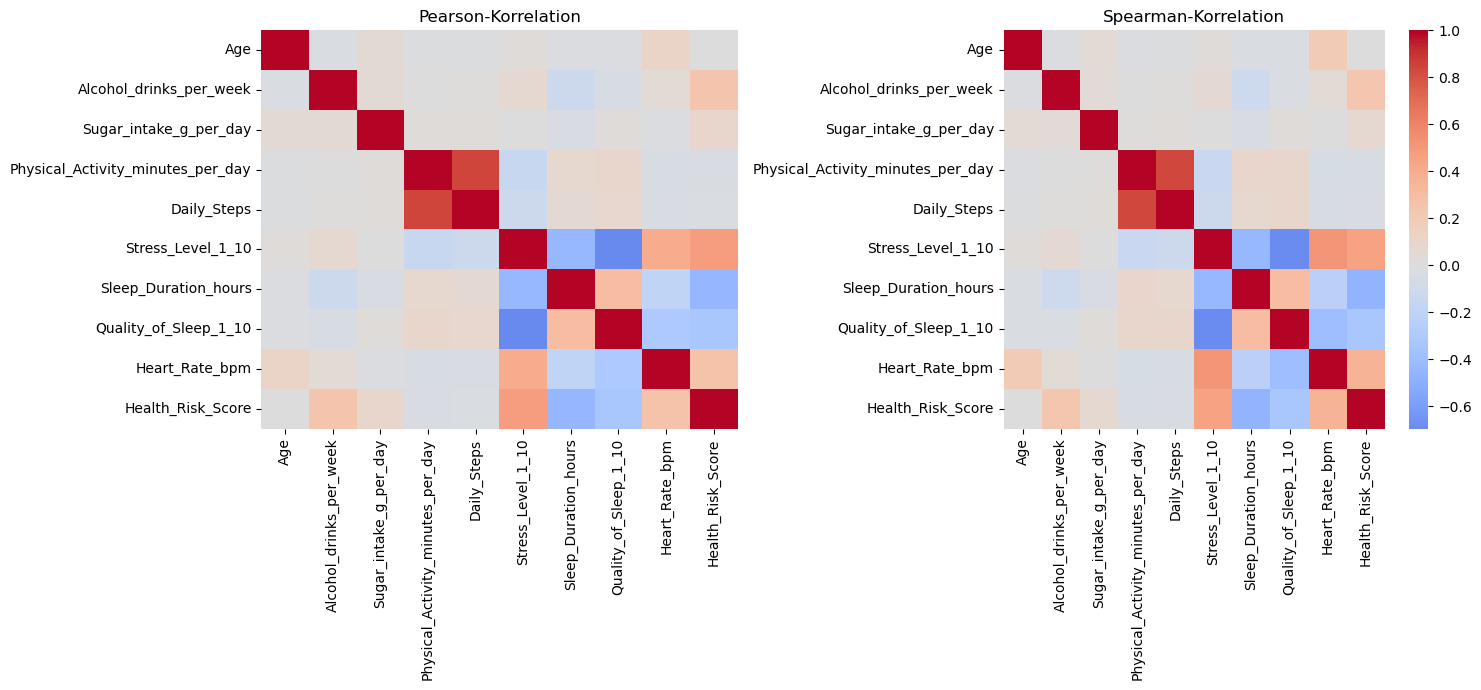

In [11]:
pearson_corr = df[num_cols].corr(method="pearson")
spearman_corr = df[num_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15,7))

sns.heatmap(
    pearson_corr,
    annot=False,
    cmap="coolwarm",
    cbar=False,
    center=0,
    ax=axes[0]
)

axes[0].set_title("Pearson-Korrelation")

sns.heatmap(
    spearman_corr,
    annot=False,
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)

axes[1].set_title("Spearman-Korrelation")

plt.tight_layout()
plt.show()

**Interpretation**  
Die beiden Matrizen zeigen nahezu identische Werte. Das bedeutet:

> Die meisten Zusammenhänge im Datensatz sind überwiegend linear und nicht stark durch Ausreißer oder Nichtlinearitäten verzerrt.

- Sehr starke positive Korrelation zeigen `Physical_Activity_minutes_per_day` <--> `Daily_Steps`: r ≈ 0.84  <br>
Hier liegt klare Redundanz vor. Für Modellierung bedeutet das, eine der beiden Variablen könnte entfallen oder beide können kombiniert werden (z.B. Aktivitätsindex).
- Moderat positiver Zusammenhänge
    - Höherer Alkoholkonsum geht mit höherem Gesundheitsrisiko einher. Das ist inhaltlich plausibel und kein statistisches Artefakt.
    - Mehr Bewegung geht mit geringerem Stress einher. inhaltlich plausibel (Bewegung wirkt stressregulierend).
    - Mehr Alkohol ist leicht mit kürzerer Schlafdauer verbunden. Der Effekt zeigt sich zwar schwach, ist aber physiologisch plausibel.

Abgesehen von der Bewegungsdimension liegen fast alle Zusammenhänge im schwachen Bereich mit einem  
Korrelationskoeffizient |r| < 0.30 .

Das bedeutet:  
- keine ausgeprägte Multikollinearität
- die meisten Variablen tragen eigenständige Information
- der Datensatz ist strukturell relativ "orthogonal"

Dass Pearson und Spearman fast identisch sind, bedeutet:
- keine starken Ausreißerprobleme
- keine ausgeprägten nichtlinearen monotone Effekte
- lineare Modelle sind grundsätzlich angemessen

Die Korrelationsanalyse zeigt:
1. Eine klare Aktivitätsdimension (Steps ↔ Physical Activity).
2. Moderaten Zusammenhang zwischen Alkohol und Gesundheitsrisiko.
3. Erwartbare, aber schwache Zusammenhänge zwischen:
   - Bewegung und Schlaf
   - Stress und Schlaf
4. Insgesamt geringe Multikollinearität.

Der Datensatz scheint sich gut zu eignen für:
- Regressionsmodelle
- Klassifikationsmodelle
- Clustering (da mehrere relativ unabhängige Dimensionen existieren)


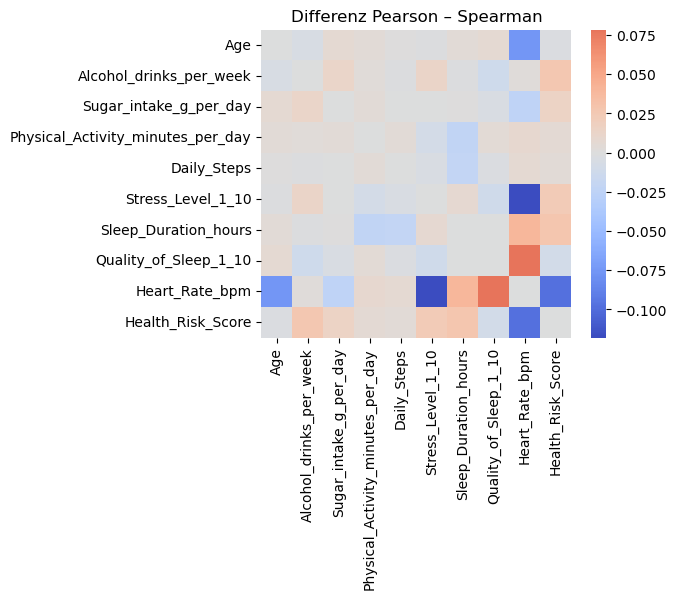

In [12]:
corr_diff = pearson_corr - spearman_corr

plt.figure(figsize=(5,4))

sns.heatmap(
    corr_diff,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Differenz Pearson – Spearman")
plt.show()

**Interpretation**  
- ≈0 → Beziehung linear
- groß → monotone, aber nicht lineare Beziehung

#### Top-Korrelationen (Redundanz-Check)
Ziel ist eine kompakte Liste der stärksten positiven und negativen Zusammenhänge, um:
- mögliche Redundanzen schnell zu erkennen
- inhaltliche Hypothesen für spätere Analysen abzuleiten

**Pearson** misst die Stärke eines linearen Zusammenhangs zwischen zwei Variablen, während **Spearman** die Stärke eines monotonen (rangbasierten) Zusammenhangs misst und damit auch nichtlineare, aber monotone Beziehungen erfassen kann.

In [13]:
# Pearson und Spearman Korrelationen
def top_correlations(corr_df, n=10):
    c = corr_df.copy()

    for i in range(len(c)):
        c.iloc[i, i] = np.nan

    stacked = c.stack().reset_index()
    stacked.columns = ["var_1", "var_2", "corr"]
    stacked["abs_corr"] = stacked["corr"].abs()

    stacked["pair"] = stacked.apply(
        lambda r: tuple(sorted([r["var_1"], r["var_2"]])),
        axis=1
    )

    stacked = stacked.drop_duplicates("pair").drop(columns=["pair"])
    return stacked.sort_values("abs_corr", ascending=False).head(n)


def highlight_top3(s):
    top3 = s.nlargest(3)
    return [
        "background-color: gold; font-weight: bold"
        if pd.notna(v) and v in top3.values else ""
        for v in s
    ]

top_pearson = top_correlations(pearson_corr, n=12)
top_spearman = top_correlations(spearman_corr, n=12)

top_pearson_renamed = top_pearson.rename(columns={
    "corr": "pearson_corr",
    "abs_corr": "pearson_abs_corr"
})

top_spearman_renamed = top_spearman.rename(columns={
    "corr": "spearman_corr",
    "abs_corr": "spearman_abs_corr"
})

comparison = pd.merge(
    top_pearson_renamed,
    top_spearman_renamed,
    on=["var_1", "var_2"],
    how="outer"
)

comparison.style.format({
    "pearson_corr": "{:.2f}",
    "spearman_corr": "{:.2f}",
    "pearson_abs_corr": "{:.2f}",
    "spearman_abs_corr": "{:.2f}"
}).background_gradient(
    subset=["pearson_abs_corr", "spearman_abs_corr"],
    cmap="Reds"
).apply(
    highlight_top3,
    subset=["pearson_abs_corr"]
).apply(
    highlight_top3,
    subset=["spearman_abs_corr"]
)

,var_1,var_2,pearson_corr,pearson_abs_corr,spearman_corr,spearman_abs_corr
0,Alcohol_drinks_per_week,Health_Risk_Score,0.26,0.26,0.23,0.23
1,Heart_Rate_bpm,Health_Risk_Score,0.26,0.26,0.36,0.36
2,Physical_Activity_minutes_per_day,Daily_Steps,0.84,0.84,0.84,0.84
3,Quality_of_Sleep_1_10,Health_Risk_Score,-0.34,0.34,-0.33,0.33
4,Quality_of_Sleep_1_10,Heart_Rate_bpm,-0.32,0.32,-0.40,0.40
5,Sleep_Duration_hours,Health_Risk_Score,-0.45,0.45,-0.48,0.48
6,Sleep_Duration_hours,Heart_Rate_bpm,-0.20,0.20,-0.24,0.24
7,Sleep_Duration_hours,Quality_of_Sleep_1_10,0.30,0.30,0.30,0.30
8,Stress_Level_1_10,Health_Risk_Score,0.48,0.48,0.45,0.45
9,Stress_Level_1_10,Heart_Rate_bpm,0.40,0.40,0.52,0.52


**Interpretation**  
- Die Tabellen zeigen die stärksten Zusammenhänge im Datensatz.
- `Daily_Steps` und `Physical_Activity_minutes_per_day` korrelieren stark, was bedeutet, dass beide dieselbe Dimension (Bewegung) abbilden. Hier liegt klare Redundanz vor. Für die Modellierung sollte eine Variable entfernt oder kombiniert werden.
- Besonders interessant sind Korrelationen von:  
  - `Stress_Level_1_10` mit `Quality_of_Sleep_1_10`
  - `Stress_Level_1_10` mit `Heart_Rate_bpm` oder `Health_Risk_Score`
  - `Sleep_Duration_hours` mit `Health_Risk_Score`

Diese liefern Anhaltspunkte für spätere Hypothesen und Modellfeatures.


#### Assoziationen zwischen kategorialen Variablen (Cramér’s V)
Ziel ist die Analyse von Zusammenhängen zwischen nominalen Variablen (z.B. `Gender`, `Smoking`, `BMI_Category`, `Health_Risk`).  
Hier ist **Cramér’s V** besser geeignet als die Pearson-Korrelation.

Cramér’s V liefert einen Wert zwischen 0 und 1: 
- 0: Kein Zusammenhang (völlige Unabhängigkeit).
- 1: Perfekter Zusammenhang (eine Variable ist vollständig durch die andere bestimmbar).

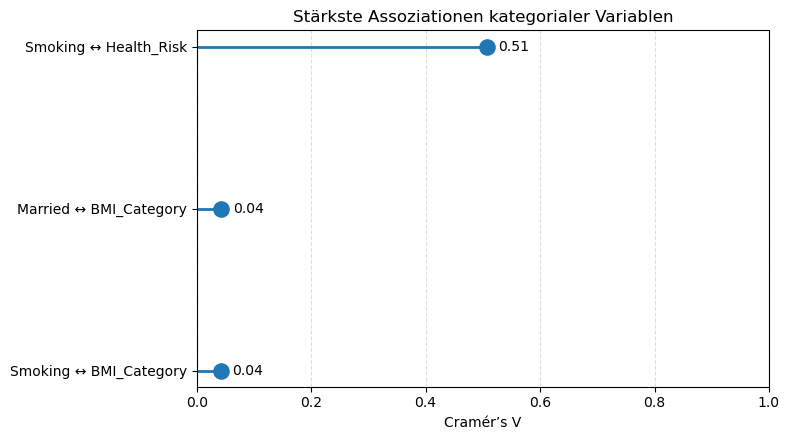

In [14]:
# Cramér's V + Lollipop-Plot der stärksten Assoziationen

from scipy.stats import chi2_contingency

# Kategoriale Spalten im Rohdaten-DataFrame df
cat_cols_raw = [
    "Gender",
    "Married",
    "Smoking",
    "BMI_Category",
    "Health_Risk"
]

# Funktion: Cramér's V

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape
    phi2 = chi2 / n

    # Bias correction
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)

    denom = min((kcorr - 1), (rcorr - 1))
    if denom <= 0:
        return np.nan

    return np.sqrt(phi2corr / denom)

# Funktion: Top-Kombinationen extrahieren

def top_cramers_v(cv_matrix, n=10):
    c = cv_matrix.copy()

    # Diagonale entfernen
    for i in range(len(c)):
        c.iloc[i, i] = np.nan

    stacked = c.stack().reset_index()
    stacked.columns = ["var_1", "var_2", "cramers_v"]

    # Doppelte Paare entfernen: (A,B) == (B,A)
    stacked["pair"] = stacked.apply(
        lambda r: tuple(sorted([r["var_1"], r["var_2"]])),
        axis=1
    )

    stacked = stacked.drop_duplicates("pair").drop(columns=["pair"])
    return stacked.sort_values("cramers_v", ascending=False).head(n)

# Cramér's-V-Matrix berechnen

if len(cat_cols_raw) >= 2:
    cv = pd.DataFrame(index=cat_cols_raw, columns=cat_cols_raw, dtype=float)

    for c1 in cat_cols_raw:
        for c2 in cat_cols_raw:
            cv.loc[c1, c2] = cramers_v(df[c1], df[c2])
else:
    cv = None
    print("Nicht genügend kategoriale Spalten für Cramér’s V.")

# Lollipop-Plot der Top-3-Assoziationen
if cv is not None:
    top_cv = top_cramers_v(cv, n=3).copy()

    top_cv["pair_label"] = top_cv["var_1"] + " ↔ " + top_cv["var_2"]
    top_cv = top_cv.sort_values("cramers_v", ascending=True).reset_index(drop=True)

    plt.figure(figsize=(8, 4.5))

    # horizontale Linien
    plt.hlines(
        y=top_cv["pair_label"],
        xmin=0,
        xmax=top_cv["cramers_v"],
        linewidth=2
    )

    # Punkte am Ende
    plt.scatter(
        top_cv["cramers_v"],
        top_cv["pair_label"],
        s=120
    )

    # Werte beschriften
    for _, row in top_cv.iterrows():
        plt.text(
            row["cramers_v"] + 0.02,
            row["pair_label"],
            f"{row['cramers_v']:.2f}",
            va="center",
            fontsize=10
        )

    plt.xlim(0, 1)
    plt.xlabel("Cramér’s V")
    plt.title("Stärkste Assoziationen kategorialer Variablen")
    plt.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

**Interpretation**  

Wie erwartet, exisitiert ein starker Zusammenhang zwischen Smoking und Health_Risk. 
> Zwischen Raucherstatus und Gesundheitsrisiko besteht ein starker Zusammenhang (Cramér’s V = 0.51).  
> Die Verteilung der Risikoklassen unterscheidet sich signifikant zwischen Rauchern und Nichtrauchern.  
> Dies deutet darauf hin, dass Rauchen ein zentraler Risikofaktor im Datensatz ist oder bei der Generierung des Health_Risk berücksichtigt wurde.

Während Cramér’s V die Stärke der Assoziation zwischen kategorialen Variablen misst, zeigen **normalisierte Kreuztabellen (Crosstab)** die konkrete Verteilung der Kategorien und ermöglichen dadurch eine inhaltliche Interpretation der Zusammenhänge.

In [15]:
pd.crosstab(df["Smoking"], df["Health_Risk"], normalize="index")

Health_Risk,High,Low,Medium
Smoking,,,
No,0.000658,0.903226,0.096116
Yes,0.213573,0.477046,0.309381


Während Nichtraucher überwiegend ein niedriges Gesundheitsrisiko aufweisen (≈90 %), zeigt sich bei Rauchern eine deutlich ungünstigere Verteilung mit rund 21 % hohem und 31 % mittlerem Risiko. 

**Rauchen verschiebt die Verteilung des Gesundheitsrisikos massiv nach oben.**

Wie verteilen sich Raucher und Nichtraucher innerhalb jeder Health-Risk-Gruppe?

In [16]:
pd.crosstab(df["Smoking"], df["Health_Risk"], normalize="columns")

Health_Risk,High,Low,Medium
Smoking,,,
No,0.009259,0.851645,0.48505
Yes,0.990741,0.148355,0.51495


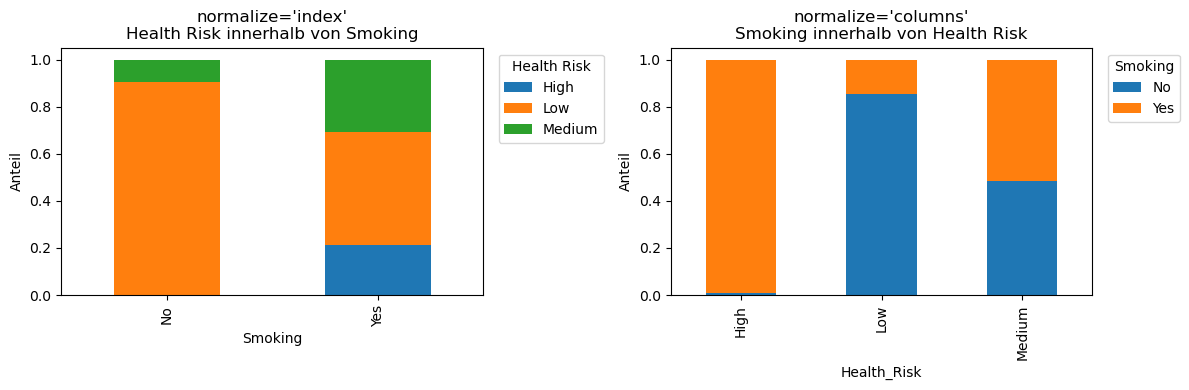

In [17]:
# crosstab
ct_index = pd.crosstab(
    df["Smoking"],
    df["Health_Risk"],
    normalize="index"
)

ct_columns = pd.crosstab(
    df["Smoking"],
    df["Health_Risk"],
    normalize="columns"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ct_index.plot(
    kind="bar",
    stacked=True,
    ax=axes[0]
)
axes[0].set_title("normalize='index'\nHealth Risk innerhalb von Smoking")
axes[0].set_ylabel("Anteil")
axes[0].legend(title="Health Risk", bbox_to_anchor=(1.02, 1), loc="upper left")

ct_columns.T.plot(
    kind="bar",
    stacked=True,
    ax=axes[1]
)
axes[1].set_title("normalize='columns'\nSmoking innerhalb von Health Risk")
axes[1].set_ylabel("Anteil")
axes[1].legend(title="Smoking", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Zur inhaltlichen Interpretation kategorialer Zusammenhänge wurden normalisierte Kreuztabellen aus zwei Perspektiven betrachtet.  
**normalize="index"** zeigt die Verteilung der Zielvariable innerhalb der Gruppen der erklärenden Variable, während  
**normalize="columns"** die Zusammensetzung der Zielgruppen hinsichtlich der erklärenden Variable beschreibt.

#### Numerische Variablen nach Kategorien (Gruppenstatistiken)
Ziel ist die Analyse, ob sich numerische Kennzahlen zwischen Gruppen unterscheiden (z.B. Schlafdauer nach Geschlecht, Stress nach Raucherstatus).<br>
Dies liefert erste Hypothesen und zeigt, welche Kategorien starke Segmentierungseffekte haben.


In [18]:
mean_by_group = (
    df.groupby("Health_Risk")[num_cols]
      .mean()
      .round(2)
)
mean_by_group.T.style.background_gradient(cmap="coolwarm")

Health_Risk,High,Low,Medium
Age,45.600000,45.670000,45.870000
Alcohol_drinks_per_week,9.530000,5.800000,8.440000
Sugar_intake_g_per_day,55.670000,48.820000,53.210000
Physical_Activity_minutes_per_day,58.610000,61.540000,58.460000
Daily_Steps,6683.030000,6917.970000,6569.000000
Stress_Level_1_10,7.780000,4.440000,6.380000
Sleep_Duration_hours,5.320000,7.210000,5.790000
Quality_of_Sleep_1_10,5.640000,7.260000,6.280000
Heart_Rate_bpm,79.620000,70.820000,75.330000
Health_Risk_Score,2.000000,0.000000,1.000000


**Interpretation**

Die Analyse der gruppierten Mittelwerte zeigt eine klare und konsistente Differenzierung der Gesundheitsrisikoklassen.  
Personen mit hohem Risiko weisen signifikant höhere Stresswerte, geringere Schlafdauer, schlechtere Schlafqualität sowie eine deutlich erhöhte Herzfrequenz auf.  

Insbesondere die Stress–Schlaf–Herzfrequenz-Dimension stellt den zentralen Strukturkern der Risikologik dar.  
Alkoholkonsum zeigt ebenfalls einen moderaten, unterstützenden Effekt, während Zuckeraufnahme nur schwach differenziert.  

Demografische Merkmale wie Alter sowie körperliche Aktivität tragen hingegen kaum zur Trennung der Risikogruppen bei.  

Insgesamt deutet die Struktur darauf hin, dass das Gesundheitsrisiko im Datensatz primär psycho-physiologisch modelliert ist und weniger durch klassische und messbare Körpermerkmale bestimmt wird.


#### Missing-Value-Analyse

Ziel ist zu prüfen, ob fehlende Werte unabhängig auftreten oder ob sich bestimmte Variablen gemeinsam "fehlen" (Hinweis auf systematische Ausfälle / Messlogik).
Dazu wird die Korrelation des Missing-Indikators (1=fehlend) betrachtet.

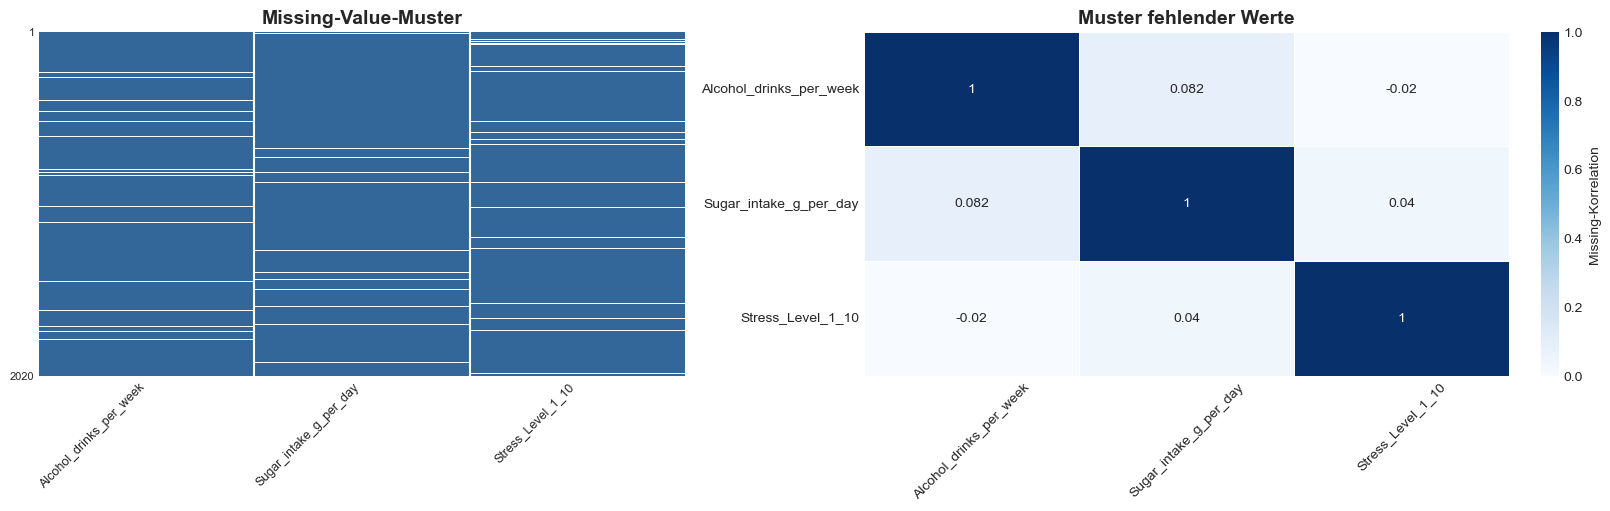

In [19]:
#missing value analysis
plt.style.use("seaborn-v0_8-white")

cols_with_missing = df.columns[df.isna().any()]
missing_ind = df.isna().astype(int)
missing_corr = missing_ind.corr().loc[cols_with_missing, cols_with_missing]

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    constrained_layout=True
)

# Linke Grafik
msno.matrix(
    df[cols_with_missing],
    sparkline=False,
    ax=axes[0],
    color=(0.2, 0.4, 0.6)
)

axes[0].set_title("Missing-Value-Muster", fontsize=14, fontweight="bold")

# X-Achse unten
axes[0].xaxis.tick_bottom()
axes[0].set_xticklabels(
    cols_with_missing,
    rotation=45,
    ha="right",
    fontsize=9
)

# Y-Achsen-Schriftgröße verkleinern
axes[0].tick_params(axis='y', labelsize=8)

# Rechte Grafik
sns.heatmap(
    missing_corr,
    annot=True,
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Missing-Korrelation"},
    ax=axes[1]
)

axes[1].set_title("Muster fehlender Werte", fontsize=14, fontweight="bold")

axes[1].xaxis.tick_bottom()
axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)

plt.show()

Die fehlenden Werte konzentrieren sich auf drei Lifestyle-Variablen und zeigen kein systematisches Ko-Auftreten.

<div style="
  border-left: 6px solid #2e7d32;
  background-color: #f1faf3;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 16px;
  line-height: 1.5;
  border-radius: 6px;
">
  <strong>Wichtig:</strong><br>
  Die Untersuchung, ob das Fehlen MCAR (Missing Completely At Random) ist oder systematisch auftritt, ist entscheidend für die Wahl der Imputationsstrategie. <br>
  Ein formaler Test auf MCAR wäre beispielsweise der Little-MCAR-Test.
</div>

Die Korrelationen zwischen den **Missing-Indikatoren** sind durchweg gering, was auf ein weitgehend unabhängiges Auftreten fehlender Werte hinweist.  
Dieses Muster ist konsistent mit der Annahme von Missing Completely at Random, sodass eine **einfache Imputation** mittels Mittelwert oder Median als pragmatisch vertretbar erscheint.

## 3. Datenbereinigung und Qualitätsanalyse

- Datentyp-Harmonisierung
- Fehlende Werte
- Duplikate
- Ausreißeranalyse
- Plausibilitätsprüfung (Konsistenzprüfung (z. B. BMI vs. Gewicht/Größe))
- Verteilungsprüfung
- Stress & Health Risk Balance


#### Datentyp-Harmonisierung

**Ziel:**  
Sicherstellen, dass jede Variable den korrekten Datentyp besitzt, bevor Bereinigung und Modellierung starten.  
Das verhindert stille Typfehler, verbessert die Auswertbarkeit (Groupby, Deskription, Plots) und macht die spätere Pipeline reproduzierbar.

**Warum an dieser Stelle?** 
Nach der strukturellen Exploration (Kapitel 2) ist klar:
- welche Spalten numerisch vs. kategorial sind,
- ob Pandas beim Einlesen Typen falsch interpretiert hat,
- welche Variablen als Kategorien behandelt werden sollten.

Vor der eigentlichen Bereinigung (Missing, Ausreißer, Plausibilität) ist die Umstellung ideal, weil:
- Regeln (z. B. Grenzwerte) datentypabhängig sind,
- Imputation/Clipping sonst ungewollte Konvertierungen auslöst,
- spätere Modellierung keine Überraschungen ergibt.

Zunächst wird geprüft, ob numerische Variablen wirklich numerisch sind und ob kategoriale Variablen als `object` vorliegen.  
Ziel ist eine kontrollierte, explizite Typdefinition statt impliziter Pandas-Automatik.

In [20]:
cat_cols = ["Gender", "Married", "Smoking", "BMI_Category", "Health_Risk"]
int_cols = ["Daily_Steps", "Health_Risk_Score"]
float_cols = [
    "Age",
    "Alcohol_drinks_per_week",
    "Sugar_intake_g_per_day",
    "Physical_Activity_minutes_per_day",
    "Stress_Level_1_10",
    "Sleep_Duration_hours",
    "Quality_of_Sleep_1_10",
    "Heart_Rate_bpm"
]

cat_cols = [c for c in cat_cols if c in df.columns]
int_cols = [c for c in int_cols if c in df.columns]
float_cols = [c for c in float_cols if c in df.columns]

for c in cat_cols:
    df[c] = df[c].astype("category")

for c in float_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")

for c in int_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")

display(df.dtypes.to_frame("dtype"))

,dtype
Age,float64
Gender,category
Married,category
Smoking,category
Alcohol_drinks_per_week,float64
Sugar_intake_g_per_day,float64
Physical_Activity_minutes_per_day,float64
Daily_Steps,Int64
Stress_Level_1_10,float64
Sleep_Duration_hours,float64


**Interpretation**
- Kategoriale Variablen sind jetzt als `category` typisiert (bessere Speicher- und Analyse-Eigenschaften).
- Numerische Variablen wurden explizit in `float64` überführt.
- Ganzzahl-Spalten (z. B. Schritte) wurden als `Int64` gesetzt (nullable Integer → erlaubt Missing-Werte).

Damit ist der Datensatz typseitig stabil und die nachfolgenden Cleaning-Schritte (Missing Values, Ausreißer, Plausibilität) laufen ohne stille Typkonvertierungen.

#### Fehlende Werte

Quantifizieren, wo und wie stark fehlende Werte auftreten und damit eine passende Imputationsstrategie ableiten.

In [21]:
# einheitliche Ergebnisdarstellung der Tests

def quality_box(title, condition, message_ok, message_warn=None):
    """
    title: Titel der Prüfung
    condition: True = OK, False = Problem
    message_ok: Text bei erfüllter Bedingung
    message_warn: Optionaler Text bei Problem
    """

    if condition:
        color = "#2e7d32"
        bg = "#f1f8f4"
        message = message_ok + " ✅"
    else:
        color = "#c62828"
        bg = "#fdecea"
        message = (message_warn if message_warn else "Problem festgestellt") + " ⚠️"

    display(HTML(f"""
    <div style="
      border-left: 6px solid {color};
      background-color: {bg};
      padding: 12px 16px;
      margin: 12px 0;
      font-size: 16px;
      border-radius: 6px;
    ">
      <strong>{title}</strong><br>
      {message}
    </div>
    """))

In [22]:
# Missing-Werte berechnen
missing_abs = df.isna().sum()
missing_abs = missing_abs[missing_abs > 0]

if len(missing_abs) == 0:
    print("✅ Keine fehlenden Werte im Datensatz vorhanden.")
else:
    missing_df = pd.DataFrame({
        "Missing (n)": missing_abs,
        "Missing (%)": (missing_abs / len(df) * 100)
    }).sort_values("Missing (%)", ascending=False)

    display(
        missing_df
        .style
        .format({"Missing (%)": "{:.2f}"})
        .background_gradient(subset=["Missing (%)"], cmap="Reds")
    )

,Missing (n),Missing (%)
Alcohol_drinks_per_week,74,3.66
Stress_Level_1_10,64,3.17
Sugar_intake_g_per_day,54,2.67


**Interpretation** 
- Niedrige Raten (< 5 %) sprechen für unkritische Missing-Strukturen.
- Die fehlenden Werte sind auf wenige Variablen begrenzt und vom Umfang her gering, daher ist Median-Imputation vertretbar.
- Für Modellierung wichtig: Missing Values müssen vor Scaling/Modelltraining behandelt werden, sonst drohen Fehler oder Verzerrungen.

Zur Behandlung fehlender Werte wurde eine **Median-Imputation** für numerische Variablen gewählt.

Die Entscheidung basiert auf folgenden Überlegungen:

1. Der Anteil fehlender Werte ist insgesamt gering (< 5 % pro betroffener Variable), sodass keine komplexen Imputationsverfahren erforderlich sind.
2. Mehrere Variablen (z. B. Alkoholkonsum, tägliche Schritte) weisen eine leichte Schiefe sowie potenzielle Extremwerte auf.
3. Der Median ist gegenüber Ausreißern robust und verzerrt die zentrale Lage der Verteilung weniger stark als der Mittelwert.

Im Vergleich zur Mean-Imputation reduziert die Median-Imputation das Risiko, die Verteilung durch einzelne extreme Beobachtungen systematisch zu verschieben.  
Da es sich überwiegend um kontinuierliche Gesundheits- und Lifestyle-Variablen handelt, stellt der Median eine konservative und stabile Schätzgröße dar.

Aufgrund der geringen Missing-Rate ist nicht davon auszugehen, dass die gewählte Imputationsstrategie die Modellierung signifikant beeinflusst.  
Die Entscheidung erhöht jedoch die Robustheit gegenüber Verteilungsanomalien und unterstützt eine stabile spätere Modellschätzung.

In [23]:
# Reset von df_clean, um erneut Datenbereigung zu demonstrieren
df_clean = df_raw.copy()

num_cols = df_clean.select_dtypes(include="number").columns
cols_with_missing = df_clean[num_cols].columns[df_clean[num_cols].isna().any()]
rows_with_missing = df_clean[cols_with_missing].isna().any(axis=1)

df_clean[num_cols] = df_clean[num_cols].fillna(df_clean[num_cols].median())

comparison = pd.concat(
    [df.loc[rows_with_missing, cols_with_missing],
     df_clean.loc[rows_with_missing, cols_with_missing]],
    axis=1,
    keys=["Original", "Imputiert"]
)

style_df = pd.DataFrame("", index=comparison.index, columns=comparison.columns)

for col in cols_with_missing:
    mask = comparison[("Original", col)].isna()
    style_df.loc[mask, ("Imputiert", col)] = "background-color: #ffe082"

comparison.style \
    .format(precision=1) \
    .apply(lambda _: style_df, axis=None)

<div style="
  border-left: 6px solid #1976d2;
  background-color: #f7fbff;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 18px;
  line-height: 1.5;
  color: #1a1a1a;
  border-radius: 6px;
">
  <strong>Grundregel:</strong><br>

  <table style="border-collapse: collapse; width: 100%; font-size: 14px;">
    <thead>
      <tr>
        <th style="text-align: left; padding: 6px; border-bottom: 2px solid #1976d2;">Situation</th>
        <th style="text-align: left; padding: 6px; border-bottom: 2px solid #1976d2;">Empfehlung</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">Symmetrische, annähernd normalverteilte Variable</td>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;"><strong>Mean</strong></td>
      </tr>
      <tr>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">Schiefe Verteilung oder Ausreißer vorhanden</td>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;"><strong>Median</strong></td>
      </tr>
      <tr>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">Ordinale Skalen (z. B. 1–10)</td>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;"><strong>Median</strong></td>
      </tr>
      <tr>
        <td style="padding: 6px;">Kleine Missing-Rate (&lt;5 %)</td>
        <td style="padding: 6px;">Beide meist unkritisch</td>
      </tr>
    </tbody>
  </table>
</div>

In [24]:
missing_total = df_clean.isna().sum().sum()

quality_box(
    "Vollständigkeit",
    missing_total == 0,
    "Keine fehlenden Werte vorhanden",
    f"{missing_total} fehlende Werte vorhanden"
)

#### Duplikate

Sicherstellen, dass jede Zeile eine eindeutige Beobachtung darstellt (keine Mehrfachzählung).
Quantifizieren, wo und wie stark fehlende Werte auftreten und damit eine passende Imputationsstrategie ableiten.

In [25]:
dup_n = df_clean.duplicated().sum()
dup_summary = pd.DataFrame({
    "Beobachtungen": [len(df_clean)],
    "Duplikate": [dup_n],
    "Duplikat-Quote (%)": [round(dup_n / len(df_clean) * 100, 2)]
})

dup_summary.style.background_gradient(subset=["Duplikate"], cmap="Reds").hide(axis="index")

Beobachtungen,Duplikate,Duplikat-Quote (%)
2020,20,0.990000


**Interpretation**
- Duplikate können Verteilungen und Modelltraining verzerren. Ihre Entfernung erhöht die Datenqualität.

In [26]:
# Duplikate entfernen, falls sie existieren
df_clean = df_clean.drop_duplicates()
# df_clean.shape

In [27]:
dup_n = df_clean.duplicated().sum()

quality_box(
    "Duplikatsprüfung",
    dup_n == 0,
    "Keine Duplikate gefunden",
    f"{dup_n} Duplikate gefunden"
)

#### Ausreißeranalyse (IQR)
Extremwerte identifizieren, die Kennzahlen/Skalierung/Modelle (v.a. lineare Modelle) negativ beeinflussen können.

In [28]:
# IQR-Ausreißerquote je numerischer Variable
num_cols = df_clean.select_dtypes(include="number").columns

# Health_Risk_Score (20.2 %) ist kein echter Ausreißerfall, sondern eine diskrete Zielvariable (0, 1, 2).
# Die IQR-Methode interpretiert die Randklassen als Ausreißer, weil sie numerisch weit vom Median entfernt liegen.
exclude = [c for c in ["Health_Risk_Score"] if c in num_cols]
num_cols_out = num_cols.drop(exclude)

outlier_info = []
for col in num_cols_out:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_rate = ((df_clean[col] < lower) | (df_clean[col] > upper)).mean() * 100
    outlier_info.append((col, round(outlier_rate, 2)))

outliers_df = (
    pd.DataFrame(outlier_info, columns=["Variable", "Outlier_in_%"])
      .sort_values("Outlier_in_%", ascending=False)
      .reset_index(drop=True)
)

# Qualitätskriterium (Daumenregel): kritisch, wenn irgendeine Variable > 5% Ausreißer hat
critical_outliers = (outliers_df["Outlier_in_%"] > 5).any()
max_out = outliers_df["Outlier_in_%"].max()

quality_box(
    "Ausreißeranalyse (IQR)",
    condition=not critical_outliers,
    message_ok=f"Keine kritischen Ausreißerquoten (max = {max_out:.2f}%)",
    message_warn=f"Kritische Ausreißerquoten erkannt (max = {max_out:.2f}%)"
)

display(
    outliers_df.style
      .hide(axis="index")
      .format({"Outlier_in_%": "{:.2f}"})
)

Variable,Outlier_in_%
Heart_Rate_bpm,0.70
Physical_Activity_minutes_per_day,0.50
Alcohol_drinks_per_week,0.50
Sugar_intake_g_per_day,0.45
Daily_Steps,0.30
Quality_of_Sleep_1_10,0.30
Age,0.25
Sleep_Duration_hours,0.25
Stress_Level_1_10,0.00


**Interpretation**
- Hohe Ausreißerquoten markieren Variablen, bei denen robuste Skalierung (RobustScaler) oder Clipping sinnvoll sein kann.
- Für Tree Models meist weniger kritisch, für lineare Modelle & Distanzverfahren (KNN/KMeans) stärker relevant.
- Alle Variablen liegen unter 1 %, was gegen systematische Extremwerte spricht.
- Es gibt keine massiven Verteilungsprobleme, die Streuung erscheint realistisch.

<div style="
  border-left: 6px solid #1976d2;
  background-color: #f7fbff;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 18px;
  line-height: 1.5;
  color: #1a1a1a;
  border-radius: 6px;
">
  <strong>Einfluss auf Modellierung:</strong><br>

  <table style="border-collapse: collapse; width: 100%; font-size: 14px;">
    <thead>
      <tr>
        <th style="text-align: left; padding: 6px; border-bottom: 2px solid #1976d2;">Modelltyp</th>
        <th style="text-align: left; padding: 6px; border-bottom: 2px solid #1976d2;">Reaktion auf Ausreißer</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">Lineare Modelle</td>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">empfindlich</td>
      </tr>
      <tr>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">KNN / KMeans</td>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">empfindlich</td>
      </tr>
      <tr>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">Tree-based Modelle</td>
        <td style="padding: 6px; border-bottom: 1px solid #ddd;">robust</td>
      </tr>
      <tr>
        <td style="padding: 6px;">Random Forest</td>
        <td style="padding: 6px;">robust</td>
      </tr>
    </tbody>
  </table>
</div>

#### Plausibilitäts- und Konsistenzprüfung
Prüfen, ob Werte in plausiblen Bereichen liegen und Skalenregeln eingehalten werden (z.B. 1–10 Skalen).

In [29]:
checks = {
    "Stress_Level_1_10": (1, 10),
    "Quality_of_Sleep_1_10": (1, 10),
    "Sleep_Duration_hours": (0, 12),
    "Heart_Rate_bpm": (30, 140),
    "Daily_Steps": (0, 50000)
}

violations_data = []

for col, (lo, hi) in checks.items():
    if col in df_clean.columns:
        v = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
        violations_data.append((col, f"{lo} – {hi}", int(v)))

# print(pd.Series(violations_data).sort_values(ascending=False))

violations_df = pd.DataFrame(
    violations_data,
    columns=["Variable", "Gültiger_Bereich", "Verstöße"]
)

violations_total = violations_df["Verstöße"].sum()

quality_box(
    "Plausibilitätsprüfung",
    violations_total == 0,
    "Alle Werte innerhalb plausibler Grenzen",
    f"{violations_total} Werte außerhalb zulässiger Bereiche"
)

display(
    violations_df
        .style
        .hide(axis="index")
        .format({"Verstöße": "{:.0f}"})
)

Variable,Gültiger_Bereich,Verstöße
Stress_Level_1_10,1 – 10,0
Quality_of_Sleep_1_10,1 – 10,0
Sleep_Duration_hours,0 – 12,5
Heart_Rate_bpm,30 – 140,5
Daily_Steps,0 – 50000,0


**Interpretation**
- außer bei der Herzfrequenz gibt es keine Verstöße, alle Wertebereiche sind konsistent und plausibel
- Verstöße (falls >0) sollten bereinigt werden (z.B. Removal/Clipping), da sie sonst Modelle/Statistiken verzerren.
- Warum wurde ein ein Wert von 200 bpm nicht als Ausreißer erkannt?

--> IQR-Methode erkennt relative Ausreißer – keine medizinischen Grenzwerte.

<div style="
  border-left: 6px solid #2e7d32;
  background-color: #f1faf3;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 16px;
  line-height: 1.5;
  border-radius: 6px;
">
  <strong>Erkenntniss:</strong><br>
  Die IQR-basierte Ausreißeranalyse identifizierte keine extremen Herzfrequenzen, da der obere Grenzwert aufgrund der hohen Streuung relativ hoch lag. <br>
  Eine ergänzende fachliche Plausibilitätsprüfung ist daher sinnvoll, um physiologisch unrealistische Werte zu identifizieren.
</div>

Bereinigung durch **Clipping** anstelle von Löschen (Stichprobengröße bleibt, Extremwerte stabilisiert)

In [30]:
df_clean["Heart_Rate_bpm"] = df_clean["Heart_Rate_bpm"].clip(upper=124)
df_clean["Sleep_Duration_hours"] = df_clean["Sleep_Duration_hours"].clip(upper=12)

#### Verteilungsprüfung (Schiefe)
Schiefe identifizieren, um ggf. Transformationen (z.B. Log) oder robuste Verfahren zu wählen.

In [31]:
# skewness = df_clean[num_cols].skew().sort_values(key=lambda s: s.abs(), ascending=False)
# skewness.round(2)

# Skewness je numerischer Variable (ohne Zielvariable)
num_cols = df_clean.select_dtypes(include="number").columns
exclude = [c for c in ["Health_Risk_Score"] if c in num_cols]
num_cols_skew = num_cols.drop(exclude)

skew_series = df_clean[num_cols_skew].skew().sort_values(key=lambda s: s.abs(), ascending=False)
skew_df = (
    skew_series.rename("Skewness")
      .reset_index()
      .rename(columns={"index": "Variable"})
)

# |Skew| > 1 = stark schief
skew_df["Stark_schief_(|skew|>1)"] = skew_df["Skewness"].abs() > 1
n_strong = int(skew_df["Stark_schief_(|skew|>1)"].sum())

quality_box(
    "Verteilungsprüfung (Schiefe)",
    condition=(n_strong == 0),
    message_ok="Keine stark schiefen Verteilungen (|skew| > 1) erkannt",
    message_warn=f"{n_strong} Variable(n) stark schief (|skew| > 1) – Transformation/Robust-Scaling prüfen"
)

display(
    skew_df.style
      .hide(axis="index")
      .format({"Skewness": "{:.2f}"})
      .apply(lambda s: ["background-color: #fdecea" if v else "" for v in s], subset=["Stark_schief_(|skew|>1)"])
)

Variable,Skewness,Stark_schief_(|skew|>1)
Heart_Rate_bpm,1.00,False
Alcohol_drinks_per_week,0.44,False
Daily_Steps,0.29,False
Sugar_intake_g_per_day,0.17,False
Physical_Activity_minutes_per_day,0.16,False
Sleep_Duration_hours,0.12,False
Stress_Level_1_10,0.11,False
Quality_of_Sleep_1_10,-0.09,False
Age,0.08,False


**Interpretation**  
- Stark schiefe Variablen (|Skew| > 1) können Scaling/lineare Modelle beeinflussen.
- Typische Maßnahmen: Log-Transformation (bei > 0), Winsorizing/Clipping oder robuste Skalierung.
- Eine Skewness größer 1 deutet auf eine rechtsschiefe Verteilung hin.

Das bedeutet:

- Die Mehrheit der Werte liegt im unteren Bereich.
- Es existieren wenige sehr hohe Werte (rechter langer Schwanz).
- Diese hohen Werte verzerren Mittelwert und Varianz.

Bei physiologischen Variablen wie Herzfrequenz ist eine solche **hohe Schiefe ungewöhnlich** und sollte geprüft werden.

Mögliche Ursachen  

1. Einzelne extreme Messwerte (z. B. > 150 bpm)
2. Eingabefehler
3. Ungleichgewicht zwischen Ruhe- und Belastungspuls

In [32]:
fig = px.histogram(
    df_clean,
    x="Heart_Rate_bpm",
    nbins=50,
    marginal="violin",
    opacity=0.8,
    title="Verteilung der Herzfrequenz mit Violin-Plot"
)

fig.update_layout(template="simple_white", title_x=0.5)
fig.show()

Der Violin-Plot der Herzfrequenz zeigt eine stark rechtsschiefe Verteilung mit hoher Dichte im unteren Pulsbereich und einem langen oberen Schwanz.  
Dies bestätigt die hohe positive Skewness und weist auf **wenige extreme Werte hin, die die Verteilung verzerren**.


#### Stress & Health Risk Balance
Prüfen, ob `Health_Risk` stark durch `Stress_Level_1_10` dominiert wird (Trennschärfe, aber auch Leakage-Risiko).

In [33]:
import nest_asyncio
nest_asyncio.apply()

In [34]:
import plotly.graph_objects as go

# Daten vorbereiten
stress_by_risk = (
    df_clean
    .groupby("Health_Risk")["Stress_Level_1_10"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

# Sortierung für bessere Lesbarkeit
order = ["Low", "Medium", "High"]
stress_by_risk["Health_Risk"] = pd.Categorical(
    stress_by_risk["Health_Risk"], categories=order, ordered=True
)
stress_by_risk = stress_by_risk.sort_values("Health_Risk")

# Plot
fig = go.Figure()

fig.add_trace(go.Bar(
    x=stress_by_risk["Health_Risk"],
    y=stress_by_risk["mean"],
    error_y=dict(
        type="data",
        array=stress_by_risk["std"],
        visible=True
    ),
    text=stress_by_risk["mean"].round(2),
    textposition="outside"
))

fig.update_layout(
    title="Stress-Level nach Health Risk",
    xaxis_title="Health Risk",
    yaxis_title="Stress (Mean ± SD)",
    template="simple_white",
    title_x=0.5,
    height=400,
    width=600
)

fig.show()

Der Stress-Level unterscheidet sich deutlich zwischen den Risikogruppen und steigt monoton mit zunehmendem Gesundheitsrisiko an.  
Der Unterschied zwischen High- und Low-Risk beträgt über drei Skalenpunkte, was auf eine **starke Trennschärfe** hindeutet.  
Stress stellt somit einen zentralen Prädiktor dar, birgt jedoch das Risiko einer Dominanz im Modell oder potenzieller Zielvariablen-Leakage.

Zur Einordnung des Unterschiedes der Mittelwerte relativ zur Streuung wird die **Effektstärke (Cohen's d)** gmessen.

In [35]:
# Stress-Trennschärfe zwischen Risiko-Klassen (Mittelwerte + Cohen's d)
stress_stats = (
    df_clean.groupby("Health_Risk")["Stress_Level_1_10"]
      .agg(["count", "mean", "std"])
      .round(2)
      .reset_index()
)

def cohens_d(x, y):
    x, y = x.dropna(), y.dropna()
    nx, ny = len(x), len(y)
    sx, sy = x.std(ddof=1), y.std(ddof=1)
    s_pooled = np.sqrt(((nx-1)*sx**2 + (ny-1)*sy**2) / (nx+ny-2))
    return (x.mean() - y.mean()) / s_pooled if s_pooled != 0 else np.nan

d_val = None
if set(["Low", "High"]).issubset(df_clean["Health_Risk"].unique()):
    d_val = cohens_d(
        df_clean.loc[df_clean["Health_Risk"] == "Low", "Stress_Level_1_10"],
        df_clean.loc[df_clean["Health_Risk"] == "High", "Stress_Level_1_10"]
    )

# Heuristik: |d| > 0.8 = großer Effekt (starke Dominanz)
dominant = (d_val is not None) and (abs(d_val) > 0.8)

quality_box(
    "Stress dominiert Health_Risk?",
    condition=not dominant,
    message_ok=f"Stress trennt nicht extrem (Cohen's d Low vs High = {d_val:.2f})" if d_val is not None else "Low/High nicht vorhanden – Dominanz nicht berechnet",
    message_warn=f"Stress trennt sehr stark (Cohen's d Low vs High = {d_val:.2f}) – ggf. Sensitivitätsanalyse ohne Stress"
)

display(
    stress_stats
      .style
      .hide(axis="index")
      .format({
          "count": "{:.0f}",
          "mean": "{:.2f}",
          "std": "{:.2f}"
      })
)

Health_Risk,count,mean,std
High,107,7.68,1.49
Low,1596,4.45,1.78
Medium,297,6.32,1.76


Die Mittelwerte der beiden Gruppen unterscheiden sich um etwa 1.84 Standardabweichungen.  
Die Effektstärke weist auf eine sehr **starke Differenz zwischen High- und Low-Risk-Gruppen** hin. Der Stress-Level unterscheidet die Gruppen um fast zwei Standardabweichungen, was auf eine außergewöhnlich hohe Trennschärfe hindeutet.

Das bedeutet zum Beispiel: Wenn man zufällig eine Person aus High und eine aus Low auswählte, wäre es sehr wahrscheinlich, dass die High-Person einen höheren Stresswert hat.

Bei Klassifikationsproblemen ist die Verteilung der Zielvariable entscheidend.

Wenn eine Klasse stark unterrepräsentiert ist, kann das Modell:
- die Mehrheitsklasse bevorzugen
- scheinbar hohe Accuracy erzielen
- aber die Minderheitsklasse schlecht erkennen

Das nennt man **Klassenimbalance**.

In [36]:
# Klassenbalance prüfen
risk_counts = df_clean["Health_Risk"].value_counts(dropna=False)
risk_share = (risk_counts / risk_counts.sum()).round(3)

balance_df = pd.DataFrame({
    "Count": risk_counts,
    "Share": risk_share
}).reset_index().rename(columns={"index": "Health_Risk"})

# simple Balance-Heuristik: kleinste Klasse sollte mind. 20% haben
min_share = balance_df["Share"].min()
balanced = (min_share >= 0.20)

quality_box(
    "Health_Risk Klassenbalance",
    condition=balanced,
    message_ok=f"Klassen sind ausreichend balanciert (min Share = {min_share:.3f})",
    message_warn=f"Klassen wirken unausgeglichen (min Share = {min_share:.3f}) – ggf. Gewichtung/Resampling"
)

display(balance_df.style.hide(axis="index").format({"Share": "{:.3f}"}))

Health_Risk,Count,Share
Low,1596,0.798
Medium,297,0.148
High,107,0.054


**Interpretation**
- Die kleinste Klasse („High“) macht nur 5,4 % der Beobachtungen aus.
- Die Mehrheit („Low“) umfasst knapp 80 %.
- Das ist eine deutliche Klassenimbalance und beeinflusst Klassifikationsmodelle (Bias zugunsten großer Klassen).
- Hohe Stress-Trennschärfe ist gut für Vorhersage, kann aber bedeuten:
  - Feature-Importances werden von Stress dominiert,
  - das Modell generalisiert evtl. schlechter auf Szenarien, in denen Stressmessung fehlt/anders ist.


**Interpretation**
- **Klassenbalance** beeinflusst Klassifikationsmodelle (Bias zugunsten großer Klassen).
- **Hohe Stress-Trennschärfe** ist gut für Vorhersage, kann aber bedeuten:
  - Feature-Importances werden von Stress dominiert,
  - das Modell generalisiert evtl. schlechter auf Szenarien, in denen Stressmessung fehlt/anders ist.
- Empfohlener Check: Modell einmal *mit* und einmal *ohne* Stress Level zu trainieren (Robustheit/Interpretierbarkeit).

Die Zielvariable weist eine deutliche Klassenimbalance auf, wobei die High-Risk-Klasse lediglich 5,4 % der Beobachtungen umfasst. Dies kann zu verzerrten Klassifikationsmodellen führen, die die Mehrheitsklasse bevorzugen. Für die Modellierung sind daher gewichtete Lernverfahren sowie geeignete Evaluationsmetriken erforderlich.

#### Variablenharmonisierung

Zur Verbesserung der Lesbarkeit und zur konsistenten Darstellung in Visualisierungen
werden Variablennamen vereinheitlicht.

Interne Spaltennamen werden technisch und kompakt gehalten. Darstellungsnamen für Visualisierungen werden separat definiert.

In [37]:
df_clean = df_clean.rename(columns={
    "Age": "age",
    "Gender": "gender",
    "Married": "married",
    "Smoking": "smoking",
    "Alcohol_drinks_per_week": "alcohol",
    "Sugar_intake_g_per_day": "sugar",
    "Physical_Activity_minutes_per_day": "activity",
    "Daily_Steps": "steps",
    "Stress_Level_1_10": "stress",
    "Sleep_Duration_hours": "sleepDuration",
    "Quality_of_Sleep_1_10": "sleepQuality",
    "Heart_Rate_bpm": "heartRate",
    "BMI_Category": "bmiCategory",
    "Health_Risk": "healthRisk",
    "Health_Risk_Score": "riskScore"
})

Die Umbenennung der Variablen dient der Harmonisierung der Nomenklatur.
Interne Variablennamen wurden technisch vereinfacht, während für Visualisierungen
separate Darstellungslabels definiert wurden.
Die inhaltliche Bedeutung der Variablen bleibt unverändert.

In [38]:
# Projekt-Konfigurationszelle nach dem Umbenennen

# Zentrale, Definition aller wichtigen Spaltenlisten und Metadaten.
# Damit bleiben die folgenden Kapitel (4–6 und später Modellierung) reproduzierbar und konsistent.

# Zielvariable(n)
target_class = "healthRisk"   # Klassifikation (Low/Medium/High)
target_score = "riskScore"    # diskreter Score (0/1/2)

# Numerische & kategoriale Spalten (automatisch)
num_cols = df_clean.select_dtypes(include="number").columns.tolist()
cat_cols = df_clean.select_dtypes(exclude="number").columns.tolist()

# Optional: Zielspalten aus Feature-Listen entfernen
num_features = [c for c in num_cols if c not in [target_score]]
all_features = [c for c in df_clean.columns if c not in [target_class, target_score]]

# Kern-Lifestyle-Set (für Profile/Plots)
lifestyle_vars = [
    "stress",
    "sleepDuration",
    "sleepQuality",
    "alcohol",
    "sugar",
    "activity",
    "steps",
    "heartRate"
]

# Soziodemografische / kategoriale Variablen
group_vars = ["gender", "married", "smoking", "bmiCategory"]

# Plausibilitätsgrenzen (Domänenregeln)
plausi_checks = {
    "stress": (1, 10),
    "sleepQuality": (1, 10),
    "sleepDuration": (0, 24),
    "heartRate": (30, 180),
    "steps": (0, 50000),
    "alcohol": (0, 50),
    "sugar": (0, 400),
    "activity": (0, 300)
}

# Plotly Labels (Achsentitel)
labels = {
    "age": "Age",
    "gender": "Gender",
    "married": "Married",
    "smoking": "Smoking",
    "bmiCategory": "BMI Category",
    "healthRisk": "Health Risk",
    "riskScore": "Health Risk Score",
    "stress": "Stress Level (1–10)",
    "sleepDuration": "Sleep Duration (hours)",
    "sleepQuality": "Sleep Quality (1–10)",
    "alcohol": "Alcohol (drinks/week)",
    "sugar": "Sugar Intake (g/day)",
    "activity": "Physical Activity (min/day)",
    "steps": "Daily Steps",
    "heartRate": "Heart Rate (bpm)"
}

vars_to_plot = [
    "stress","sleepDuration","sleepQuality",
    "alcohol","sugar","activity",
    "steps","heartRate","age"
]

risk_col = "healthRisk"

risk_order = ["Low","Medium","High"]

RISK_COLORS = {
    "Low": "#1f77b4",
    "Medium": "#ff7f0e",
    "High": "#d62728"
}

risk_vals = [r for r in risk_order if r in df_clean[risk_col].unique()]

def skew_iqr_stats(s):
    s = s.dropna()
    return (
        float(s.skew()),
        float(s.quantile(0.25)),
        float(s.quantile(0.75)),
        float(s.median())
    )

# Sanity-Check: Gibt es fehlende Spalten in den Listen?
missing_lifestyle = [c for c in lifestyle_vars if c not in df_clean.columns]
missing_groups = [c for c in group_vars if c not in df_clean.columns]
assert not missing_lifestyle, f"Fehlende Lifestyle-Spalten: {missing_lifestyle}"
assert not missing_groups, f"Fehlende Group-Spalten: {missing_groups}"

print("✅ Projekt-Konfiguration geladen.")
print(f"Numerische Spalten: {len(num_cols)} | Kategoriale Spalten: {len(cat_cols)}")




✅ Projekt-Konfiguration geladen.
Numerische Spalten: 10 | Kategoriale Spalten: 5


Diese Konfigurationszelle verhindert Probleme, wie :
- veraltete Feature-Listen nach Umbenennung
- inkonsistente Spaltennamen zwischen Kapiteln
- wiederholte Definitionen an mehreren Stellen

Ab Kapitel 4 werden Variablenlisten (z. B. `lifestyle_vars`) und Achsenbeschriftungen (`label`) immer aus dieser Zelle referenziert.

## 4. Populations- & Profilanalyse
Ziel dieses Kapitels ist die inhaltliche Charakterisierung der Population.
Im Fokus stehen typische Lifestyle-Profile und strukturelle Muster innerhalb der Stichprobe.

Zunächst einen **Populationsüberblick**. Es erfolgt keine erneute Qualitätsprüfung oder Korrelationsanalyse.

In [39]:
# Histogramme 3x3 (Risk Overlay + Skew + IQR + Median)
rows, cols = 3, 3

subplot_titles = []
stats = {}
for v in vars_to_plot:
    skew, q1, q3, med = skew_iqr_stats(df_clean[v])
    stats[v] = (skew, q1, q3, med)
    subplot_titles.append(f"{labels.get(v, v)}<br><span style='font-size:12px'>skew={skew:.2f}</span>")

fig_hist = make_subplots(
    rows=rows,
    cols=cols,
    subplot_titles=subplot_titles,
    horizontal_spacing=0.06,
    vertical_spacing=0.10
)

r = c = 1
for v in vars_to_plot:
    skew, q1, q3, med = stats[v]

    # gemeinsame Bins pro Variable
    vmin = df_clean[v].min()
    vmax = df_clean[v].max()
    nbins = 30
    bin_size = (vmax - vmin) / nbins if vmax > vmin else 1

    for rv in risk_vals:
        fig_hist.add_trace(
            go.Histogram(
                x=df_clean.loc[df_clean[risk_col] == rv, v],
                name=str(rv),
                marker=dict(color=RISK_COLORS.get(rv, "#888")),
                #histnorm="percent", # or "probability density"
                opacity=0.55,
                xbins=dict(start=vmin, end=vmax, size=bin_size),
                showlegend=(v == vars_to_plot[0])
            ),
            row=r, col=c
        )

    fig_hist.add_vrect(
        x0=q1, x1=q3,
        fillcolor="rgba(0,0,0,0.08)",
        line_width=0,
        row=r, col=c
    )

    fig_hist.add_vline(
        x=med,
        line_width=1.2,
        line_dash="dash",
        line_color="black",
        row=r, col=c
    )

    c += 1
    if c > cols:
        c = 1
        r += 1

fig_hist.update_layout(
    title="Verteilungen (Risk-Overlay) + Skewness + IQR + Median",
    title_x=0.5,
    template="simple_white",
    barmode="overlay",
    bargap=0.08,
    height=900,
    width=1200,
    legend_title_text="Health Risk"
)

fig_hist.show()

Andere 3×3-Darstellung, die pro Variable die Verteilungen nach Risiko-Gruppe zeigt und dabei mehrere Informationen kombiniert:
- Violinplot → Form der Verteilung
- Boxplot → Median, IQR, Ausreißer
- Gruppierung nach Health Risk

In [40]:
# 3x3 Violin und Boxplot
vars_to_plot = [
    "stress", "sleepDuration", "sleepQuality",
    "alcohol", "sugar", "activity",
    "steps", "heartRate", "age"
]

risk_col = "healthRisk"

RISK_COLORS = {
    "Low":    "#1f77b4",
    "Medium": "#ff7f0e",
    "High":   "#d62728",
}

risk_order = ["Low", "Medium", "High"]
risk_vals = [r for r in risk_order if r in df_clean[risk_col].unique()]

rows, cols = 3, 3

fig_dist = make_subplots(
    rows=rows,
    cols=cols,
    subplot_titles=[labels.get(v, v) for v in vars_to_plot],
    horizontal_spacing=0.06,
    vertical_spacing=0.10
)

r = c = 1
for v in vars_to_plot:
    for rv in risk_vals:
        mask = df_clean[risk_col] == rv
        yvals = df_clean.loc[mask, v].dropna()

        # Violinplot
        fig_dist.add_trace(
            go.Violin(
                x=[rv] * len(yvals),
                y=yvals,
                name=str(rv),
                legendgroup=str(rv),
                scalegroup=v,
                line_color=RISK_COLORS.get(rv, "#888"),
                fillcolor=RISK_COLORS.get(rv, "#888"),
                opacity=0.45,
                width=0.9,
                box_visible=True,         # Boxplot im Violinplot
                meanline_visible=True,    # Mittelwert-Linie
                points="outliers",        # nur Ausreißer anzeigen
                pointpos=0,
                jitter=0.05,
                showlegend=(v == vars_to_plot[0])
            ),
            row=r, col=c
        )

    # Kategorien je Subplot fixieren
    fig_dist.update_xaxes(
        categoryorder="array",
        categoryarray=risk_order,
        row=r, col=c
    )

    c += 1
    if c > cols:
        c = 1
        r += 1

fig_dist.update_layout(
    title="Verteilungen numerischer Variablen nach Health Risk (Violin + Boxplot)",
    title_x=0.5,
    template="simple_white",
    height=950,
    width=1250,
    legend_title_text="Health Risk",
    violinmode="group"
)

fig_dist.show()

Die Violin-Plots zeigen deutlich, wie verschiedene Lebensstilfaktoren und biologische Marker mit dem allgemeinen Gesundheitsrisiko (Health Risk) korrelieren.

**1. Deutliche Trends (Starke Korrelation)**
- **Stress Level**: Es gibt einen klaren Aufwärtstrend. Personen mit hohem Gesundheitsrisiko (High) haben signifikant höhere Stresswerte als die "Low"-Gruppe.
- **Schlaf (Duration & Quality)**: Sowohl die Schlafdauer als auch die Schlafqualität sinken merklich, wenn das Gesundheitsrisiko steigt. Die "Low Risk"-Gruppe schläft meist zwischen 7 und 8 Stunden, während die "High Risk"-Gruppe oft deutlich darunter liegt.
- **Herzfrequenz (Heart Rate)**: Mit steigendem Risiko erhöht sich auch die Ruheherzfrequenz. Das ist oft ein Indikator für geringere kardiovaskuläre Fitness oder chronischen Stress.

**2. Lebensstilfaktoren**  
- **Zuckerkonsum (Sugar Intake)**: Der Median des Zuckerkonsums steigt mit dem Risiko an. Die "High Risk"-Gruppe weist hier eine breitere Verteilung bei höheren Werten auf.
- **Bewegung (Daily Steps & Physical Activity)**: Wie zu erwarten, bewegen sich Personen mit geringem Risiko mehr. Besonders bei den täglichen Schritten sieht man, dass die "Low Risk"-Gruppe konstanter höhere Werte erreicht.
- **Alkohol**: Hier ist der Trend etwas subtiler, aber die "High Risk"-Gruppe zeigt tendenziell Ausreißer nach oben (mehr Drinks pro Woche).

**3. Überraschende oder stabile Faktoren** 
- **Alter (Age)**: Interessanterweise ist die Altersverteilung über alle drei Risikogruppen hinweg relativ ähnlich. Das deutet darauf hin, dass in diesem Datensatz das Gesundheitsrisiko stärker von Lebensstilentscheidungen (Stress, Schlaf, Ernährung) abhängt als rein vom biologischen Alter.

### 4.1 Typische Lifestyle-Profile

Identifikation charakteristischer Kombinationen von Lifestyle-Variablen.  
Nicht Einzelvariablen stehen im Vordergrund, sondern multidimensionale Muster.  

Untersucht werden kombinierte Profile aus:
- Stress
- Sleep Duration
- Sleep Quality
- Alcohol
- Physical Activity
- Heart Rate

Die Profile werden nach `healthRisk` verglichen.

**Schritt 1 – Standardisierung der Profilvariablen**

Die Variablen werden standardisiert (z-Transformation), um unterschiedliche Skalen vergleichbar zu machen.  
Damit repräsentieren die Werte Abweichungen vom Gesamtmittel in Standardabweichungen.

In [41]:
profile_vars = [
    "stress",
    "sleepDuration",
    "sleepQuality",
    "alcohol",
    "activity",
    "heartRate"
]

scaler = StandardScaler()

scaled_df = pd.DataFrame(
    scaler.fit_transform(df_clean[profile_vars]),
    columns=profile_vars
)

scaled_df["healthRisk"] = df_clean["healthRisk"]

**Schritt 2 - Mittelwertprofile nach Health Risk**

In [42]:
profile_means = (
    scaled_df.groupby("healthRisk")[profile_vars]
    .mean()
    .round(2)
    .reset_index()
)

profile_means

,healthRisk,stress,sleepDuration,sleepQuality,alcohol,activity,heartRate
0,High,1.40,-1.18,-0.98,0.66,-0.09,1.09
1,Low,-0.23,0.24,0.17,-0.13,0.02,-0.17
2,Medium,0.71,-0.84,-0.54,0.45,-0.08,0.50


Die Tabelle zeigt das **durchschnittliche standardisierte Lifestyle-Profil pro Risikoklasse**.

Positive Werte:
→ Überdurchschnittliche Ausprägung

Negative Werte:
→ Unterdurchschnittliche Ausprägung

Damit wird sichtbar, welche Dimensionen pro Klasse systematisch verschoben sind.

**Visualisierung**

In [43]:
# Radar Diagramm
categories = ["stress", "sleepDuration", "sleepQuality", "alcohol", "activity", "heartRate"]
theta = [labels.get(v, v) for v in categories]

# profile_means = (
#     scaled_df.groupby("healthRisk")[categories]
#       .mean()
#       .round(2)
#       .reset_index()
# )

fig = go.Figure()

for _, row in profile_means.iterrows():
    r = row[categories].tolist()
    fig.add_trace(go.Scatterpolar(
        r=r + [r[0]],
        theta=theta + [theta[0]],
        fill="toself",
        name=row["healthRisk"]
    ))

fig.update_layout(
    polar=dict(
        radialaxis=dict(
            visible=True,
            autorange=True 
        )
    ),
    template="simple_white",
    width=750,
    height=650,
    title="Standardisierte Lifestyle-Profile nach Health Risk",
    title_x=0.5,
    legend_title_text="Health Risk"
)

fig.show()

**Interpretation**

Das Radar-Diagramm zeigt die multidimensionalen Profile der Risikogruppen.  
Wichtige Beobachtungen:  

- High Risk:
  - deutlich erhöhter Stress
  - reduzierte Schlafdauer
  - geringere Schlafqualität
  - erhöhte Herzfrequenz
- Low Risk:
  - gegensätzliches Profil
- Medium Risk:
  - Zwischenposition

Es entsteht kein Einzelmerkmal-Effekt, sondern ein konsistentes Belastungsmuster.

- Jeder „Radiuswert“ ist ein z-standardisierter Gruppenmittelwert:
  - **> 0** = über dem Populationsmittel
  - **< 0** = unter dem Populationsmittel
- Entscheidend ist nicht ein einzelner Ausschlag, sondern die **Form**:
  - High Risk wirkt typischerweise als **Kombination** aus höherem Stress + schlechterer Schlafdimension + höherer Herzfrequenz (wenn so sichtbar).
  - Medium Risk ist als Zwischenprofil erkennbar
  - Low Risk zeigt das Gegenprofil


**Radar ist intuitiv, Balken sind analytisch klarer.**

In [44]:
# Bar Plot

melted_profiles = profile_means.melt(
    id_vars="healthRisk",
    value_vars=profile_vars,
    var_name="Variable",
    value_name="Standardized Mean"
)

fig = px.bar(
    melted_profiles,
    x="Variable",
    y="Standardized Mean",
    color="healthRisk",
    barmode="group",
    template="simple_white",
    title="Vergleich standardisierter Lifestyle-Profile",
    labels=labels
)

fig.update_layout(title_x=0.5)
fig.show()

**Interpretation**

Das gruppierte Balkendiagramm ermöglicht eine präzise quantitative Bewertung der Profilunterschiede.

Zentrale Erkenntnisse:

- Stress und Sleep-Dimensionen zeigen die stärkste Differenz.
- Heart Rate folgt dem Stress-Muster.
- Alcohol und Activity wirken unterstützend, aber weniger dominant.
- Medium Risk bildet ein konsistentes Zwischenprofil.

Damit lassen die folgende **Leitfragen** beantworten:

**Wie sieht ein typisches High-Risk-Profil aus?**  
→ Hoher Stress, kurze Schlafdauer, geringe Schlafqualität, erhöhte Herzfrequenz.

**Welche Kombinationen sind auffällig?**  
→ Stress + Schlafdimension + Herzfrequenz bilden ein zusammenhängendes Belastungsmuster.

### 4.2 Subgruppen-Charakterisierung

Ziel:
Untersuchung von Lebensstilprofilen nach soziodemografischen Gruppen.

- Gender-Profile
- Married vs Non-Married
- BMI_Category


Nicht nur Mittelwerte – sondern Mustervergleich.

Ziel:  
Charakterisierung typischer Lifestyle-Profile **innerhalb relevanter Subgruppen** (z. B. Gender, Married, BMI-Kategorie).
Im Fokus stehen **kombinierte Muster** (Profile), nicht Einzelvariablen.

Wir vergleichen Profile jeweils:
- **zwischen den Ausprägungen** einer Subgruppe (z. B. Female vs Male)
- optional **nach Health Risk** innerhalb der Subgruppe (Facetten/Color)

Verwendete Profilvariablen:
- Stress
- Sleep Duration
- Sleep Quality
- Alcohol
- Physical Activity
- Heart Rate

**Schritt 1 – Standardisierung der Profilvariablen (global)**

Ziel:  
Vergleichbarkeit sicherstellen, da die Variablen unterschiedliche Skalen haben.
Wir standardisieren **einmal global** (über alle Beobachtungen), damit Subgruppenprofile auf derselben Referenz basieren.

In [45]:
profile_vars = ["stress", "sleepDuration", "sleepQuality", "alcohol", "activity", "heartRate"]

scaler = StandardScaler()
scaled = pd.DataFrame(
    scaler.fit_transform(df_clean[profile_vars]),
    columns=profile_vars,
    index=df_clean.index
)

# Subgruppen- und Zielspalten anhängen
scaled["healthRisk"] = df_clean["healthRisk"]
scaled["gender"] = df_clean["gender"]
scaled["married"] = df_clean["married"]
scaled["bmiCategory"] = df_clean["bmiCategory"]

profile_by_risk = (
    scaled
    .groupby("healthRisk")[profile_vars]
    .mean()
    .round(2)
)

profile_by_risk

,stress,sleepDuration,sleepQuality,alcohol,activity,heartRate
healthRisk,,,,,,
High,1.40,-1.18,-0.98,0.66,-0.09,1.09
Low,-0.23,0.24,0.17,-0.13,0.02,-0.17
Medium,0.71,-0.84,-0.54,0.45,-0.08,0.50


In [46]:
profile_by_gender = (
    scaled
    .groupby("gender")[profile_vars]
    .mean()
    .round(2)
)
profile_by_gender

,stress,sleepDuration,sleepQuality,alcohol,activity,heartRate
gender,,,,,,
Female,0.04,-0.01,-0.03,-0.01,0.01,0.0
Male,-0.04,0.01,0.03,0.01,-0.01,-0.0


In [47]:
profile_by_bmi = (
    scaled
    .groupby("bmiCategory")[profile_vars]
    .mean()
    .round(2)
)
profile_by_bmi

,stress,sleepDuration,sleepQuality,alcohol,activity,heartRate
bmiCategory,,,,,,
Normal,0.00,0.01,-0.01,-0.01,0.01,0.02
Overweight,-0.07,-0.01,0.11,0.05,-0.19,-0.14
Underweight,0.34,-0.51,-0.12,0.15,0.37,0.08


**Interpretation**
Die Standardisierung erfolgt **vor** der Subgruppenaggregation.
Damit bedeuten positive/negative Profilwerte weiterhin:
- **> 0**: über dem Populationsdurchschnitt
- **< 0**: unter dem Populationsdurchschnitt

So lassen sich Subgruppenprofile direkt miteinander vergleichen.

**Schritt 2 – Profilmittelwerte je Subgruppe berechnen**

Ziel:  
Für jede Subgruppe (Gender / Married / BMI) ein kompaktes Profil berechnen.

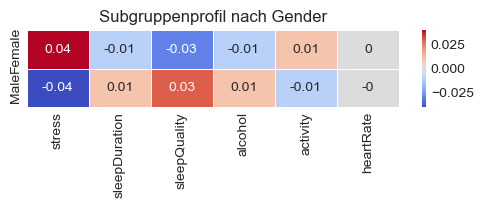

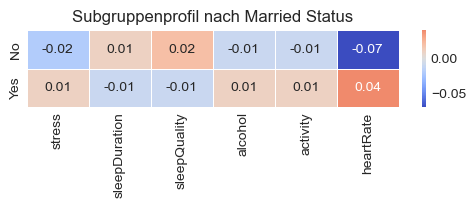

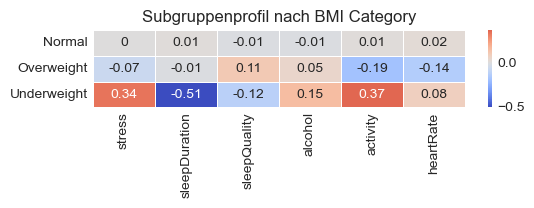

In [48]:
def subgroup_profile_means(df_scaled, group_col, vars_=profile_vars):
    return (
        df_scaled.groupby(group_col)[vars_]
        .mean()
        .round(2)
        .reset_index()
    )

gender_profiles  = subgroup_profile_means(scaled, "gender")
married_profiles = subgroup_profile_means(scaled, "married")
bmi_profiles     = subgroup_profile_means(scaled, "bmiCategory")


def plot_profile_heatmap(profile_df, title):

    df_plot = profile_df.set_index(profile_df.columns[0])

    plt.figure(figsize=(6,1))

    sns.heatmap(
        df_plot,
        annot=True,
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )

    plt.title(title)
    plt.ylabel("")
    plt.xlabel("")

    plt.show()


plot_profile_heatmap(gender_profiles, "Subgruppenprofil nach Gender")
plot_profile_heatmap(married_profiles, "Subgruppenprofil nach Married Status")
plot_profile_heatmap(bmi_profiles, "Subgruppenprofil nach BMI Category")

**Interpretation**

Die dargestellten Werte sind **z-standardisierte Mittelwerte**. Positive Werte zeigen überdurchschnittliche Ausprägungen, negative Werte unterdurchschnittliche Ausprägungen relativ zur Gesamtpopulation.


##### 1. Subgruppenprofil nach Gender

Diese Heatmap zeigt nahezu **spiegelbildliche Muster** für Frauen und Männer.

- **Stress:**  
  Frauen weisen einen positiven Wert auf *(0.04)*, während Männer einen negativen Wert *(-0.04)* zeigen.

- **Schlafqualität:**  
  Hier zeigt sich das umgekehrte Muster. Männer haben einen höheren positiven Wert *(0.03)* als Frauen *(-0.03)*.


##### 2. Subgruppenprofil nach Familienstand (Married Status)

Die Unterschiede zwischen **verheirateten** und **nicht verheirateten** Personen sind besonders deutlich bei der Herzfrequenz.

- **Herzfrequenz:**  
  Nicht verheiratete Personen zeigen einen deutlich niedrigeren Wert *(-0.07)*, während verheiratete Personen einen höheren Wert *(0.04)* aufweisen.

- **Stress:**  
  Nicht verheiratete Personen tendieren zu niedrigerem Stress *(-0.02)*, während verheiratete Personen leicht erhöhte Stresswerte *(0.01)* zeigen.


##### 3. Subgruppenprofil nach BMI-Kategorie

Diese Heatmap zeigt die **stärksten Abweichungen vom Durchschnitt**, insbesondere in der Kategorie Untergewicht.

- **Untergewicht:**  
  Diese Gruppe weist mehrere extreme Werte auf:

  - **Positiv:** Stress *(0.34)* und körperliche Aktivität *(0.37)*  
  - **Negativ:** deutlich verkürzte Schlafdauer *(-0.51)*

- **Übergewicht:**  
  Diese Gruppe zeigt vor allem:

  - geringere körperliche Aktivität *(-0.19)*  
  - niedrigere Herzfrequenz *(-0.14)*  
  - leicht erhöhte Schlafqualität *(0.11)*

- **Normalgewicht:**  
  Diese Gruppe weist die **geringsten Abweichungen vom Gesamtdurchschnitt** auf (Werte nahe *0*).


**Schritt 3 – Profilvergleich als gruppiertes Balkendiagramm**

Ziel:  
Subgruppenprofile präzise und vergleichbar darstellen.
Balkendiagramme eignen sich hier oft besser als Radar, weil Unterschiede pro Dimension klar ablesbar sind.

In [49]:
def plot_profile_bars(profile_df, group_col, title):
    long = profile_df.melt(
        id_vars=group_col,
        value_vars=profile_vars,
        var_name="Variable",
        value_name="StdMean"
    )
    fig = px.bar(
        long,
        x="Variable",
        y="StdMean",
        color=group_col,
        labels=labels,
        barmode="group",
        template="simple_white",
        title=title
    )
    fig.update_layout(title_x=0.5, height=450, width=1000)
    fig.show()

plot_profile_bars(gender_profiles,  "gender",      "Lifestyle-Profile nach Gender (standardisiert)")
plot_profile_bars(married_profiles, "married",     "Lifestyle-Profile nach Married (standardisiert)")
plot_profile_bars(bmi_profiles,     "bmiCategory", "Lifestyle-Profile nach BMI Category (standardisiert)")

**Interpretation** (Auswertungslogik)  

Für jedes Subgruppen-Plot gilt:

- Werte **> 0** = über dem Populationsdurchschnitt (in dieser Dimension)
- Werte **< 0** = darunter

Auswertung erfolgt als Profilmuster:
- **Belastungsprofil**: Stress ↑, Heart Rate ↑, Sleep Duration ↓, Sleep Quality ↓
- **Regenerationsprofil**: Sleep Duration ↑, Sleep Quality ↑, Stress ↓
- **Verhaltensprofil**: Alcohol ↑/↓, Activity ↑/↓

Wichtig:
Wir interpretieren nicht „Gender verursacht …“, sondern beschreiben Musterunterschiede.

**Schritt 4 – Optional: Subgruppe *und* Health Risk (Facetten / Risk-Overlay)**

Ziel:  
Prüfen, ob sich die Health-Risk-Profile innerhalb einer Subgruppe ähnlich oder unterschiedlich ausprägen.
Beispiel: Unterscheidet sich das High-Risk-Profil bei Female vs Male?

In [50]:
def subgroup_by_risk_profiles(df_scaled, subgroup_col):
    means = (
        df_scaled.groupby([subgroup_col, "healthRisk"])[profile_vars]
        .mean()
        .round(2)
        .reset_index()
    )
    long = means.melt(
        id_vars=[subgroup_col, "healthRisk"],
        value_vars=profile_vars,
        var_name="Variable",
        value_name="StdMean"
    )
    fig = px.bar(
        long,
        x="Variable",
        y="StdMean",
        color="healthRisk",
        labels=labels,
        facet_col=subgroup_col,
        facet_col_wrap=3,
        barmode="group",
        template="simple_white",
        title=f"Profile nach Health Risk – facettiert nach {subgroup_col}"
    )
    fig.update_layout(title_x=0.5, height=520, width=1200)
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
    fig.show()

subgroup_by_risk_profiles(scaled, "gender")
subgroup_by_risk_profiles(scaled, "married")
subgroup_by_risk_profiles(scaled, "bmiCategory")

**Interpretation**

Die Facettenplots zeigen, ob die Risk-Profile **innerhalb** einer Subgruppe stabil sind oder variieren.

- Ähnliches High-Risk-Profil in allen Subgruppen → eher „universelles“ Belastungsmuster.
- Deutliche Unterschiede zwischen Subgruppen → Hinweis auf mögliche Interaktionseffekte (Kapitel 5).

Diese Ergebnisse dienen als Brücke:  
Kapitel 4 beschreibt **Profile**, Kapitel 5 prüft explorativ **Interaktionen und Moderation**.

- Subgruppen-Profile machen sichtbar, ob bestimmte Populationsteile systematisch andere Lifestyle-Muster aufweisen.
- In Kombination mit `healthRisk` lassen sich Unterschiede im Belastungsprofil innerhalb von Subgruppen erkennen.
- Auffällige Unterschiede sind Kandidaten für Interaktionsanalysen in Kapitel 5.

### 4.3 Verhaltensmuster & Kombinationen

Ziel: 
Identifikation kritischer Kombinationen von Verhaltensweisen.  
Im Fokus stehen nicht Einzelvariablen, sondern riskante Verhaltenskonstellationen.  

Beispielhafte Kombinationen:
- Hoher Stress + kurze Schlafdauer
- Hoher Alkohol + schlechte Schlafqualität
- Niedrige Bewegung + hohe Herzfrequenz

Die Analyse erfolgt visuell über:
- 2D-Scatterplots mit Farbcodierung
- Quadrantenanalyse zur Musterklassifikation

**Schritt 1 – Definition "kritischer Kombinationen"**

Wir definieren "hoch" und "niedrig" relativ zum Median.

In [51]:
# Median-basierte Schwellenwerte
thresholds = {
    "stress": df_clean["stress"].median(),
    "sleepDuration": df_clean["sleepDuration"].median(),
    "sleepQuality": df_clean["sleepQuality"].median(),
    "alcohol": df_clean["alcohol"].median(),
    "activity": df_clean["activity"].median(),
    "heartRate": df_clean["heartRate"].median()
}

thresholds

{'stress': np.float64(4.8),
 'sleepDuration': np.float64(6.9),
 'sleepQuality': np.float64(7.1),
 'alcohol': np.float64(6.1),
 'activity': np.float64(60.7),
 'heartRate': np.float64(72.0)}

Median-basierte Schwellen sind robust gegenüber Ausreißern.   
Damit wird "überdurchschnittlich" vs. "unterdurchschnittlich" **relativ zur Population** definiert.

In [52]:
x_med = thresholds["stress"]
y_med = thresholds["sleepDuration"]

fig = px.scatter(
    df_clean,
    x="stress",
    y="sleepDuration",
    color="healthRisk",
    opacity=0.7,
    template="simple_white",
    title="Stress vs Sleep Duration – Quadrantenanalyse",
    labels=labels
)

# Medianlinien
fig.add_vline(x=x_med, line_width=2, line_dash="dash", line_color="black")
fig.add_hline(y=y_med, line_width=2, line_dash="dash", line_color="black")

# Kritischer Quadrant (hoher Stress + kurze Schlafdauer)
fig.add_shape(
    type="rect",
    x0=x_med,
    x1=df_clean["stress"].max(),
    y0=df_clean["sleepDuration"].min(),
    y1=y_med,
    fillcolor="red",
    opacity=0.08,
    layer="below",
    line_width=0
)

# Quadrantenlabels
fig.add_annotation(x=x_med*1.5, y=y_med*0.5,
                   text="Hoher Stress\n+ kurze Schlafdauer",
                   showarrow=False,
                   font=dict(size=12, color="darkred"))

fig.update_layout(title_x=0.5)

fig.show()

**Interpretation**

Die gestrichelten Linien teilen den Raum in vier Quadranten:

- Oben links: niedriger Stress + lange Schlafdauer (Regenerationsprofil)
- Unten rechts: hoher Stress + kurze Schlafdauer (Belastungsprofil)
- Andere Quadranten: Mischformen

Besonders relevant ist der Quadrant:
**Hoher Stress + kurze Schlafdauer**  
→ potenziell kritisches Belastungsmuster.

Die sichtbare Häufung von High-Risk-Personen im rot schattierten Bereich weist auf eine **relevante Verhaltenskombination** hin.

In [53]:
x_med = thresholds["alcohol"]
y_med = thresholds["sleepQuality"]

fig = px.scatter(
    df_clean,
    x="alcohol",
    y="sleepQuality",
    color="healthRisk",
    opacity=0.7,
    template="simple_white",
    title="Alcohol vs Sleep Quality – Quadrantenanalyse",
    labels=labels
)

fig.add_vline(x=x_med, line_width=2, line_dash="dash", line_color="black")
fig.add_hline(y=y_med, line_width=2, line_dash="dash", line_color="black")

fig.add_shape(
    type="rect",
    x0=x_med,
    x1=df_clean["alcohol"].max(),
    y0=df_clean["sleepQuality"].min(),
    y1=y_med,
    fillcolor="red",
    opacity=0.08,
    layer="below",
    line_width=0
)

fig.add_annotation(
    x=x_med + (df_clean["alcohol"].max() - x_med) * 0.35,
    y=df_clean["sleepQuality"].min() + (y_med - df_clean["sleepQuality"].min()) * 0.15,
    text="Hoher Alkoholkonsum\n+ niedrige Schlafqualität",
    showarrow=False,
    font=dict(size=12, color="darkred")
)

fig.update_layout(title_x=0.5)
fig.show()

**Interpretation**

Der rot schattierte Bereich markiert das kombinierte Risikomuster: **hoher Alkoholkonsum bei gleichzeitig niedriger Schlafqualität**.

Eine sichtbare Häufung von High-Risk-Beobachtungen in diesem Quadranten würde darauf hindeuten, dass Alkohol nicht isoliert wirkt, sondern vor allem in Kombination mit schlechter Schlafqualität relevant ist.

In [54]:
# Schwellen
x_med = thresholds["activity"]     # Aktivität niedrig = links
y_med = thresholds["heartRate"]    # Herzfrequenz hoch = oben

fig = px.scatter(
    df_clean,
    x="activity",
    y="heartRate",
    color="healthRisk",
    opacity=0.7,
    template="simple_white",
    title="Physical Activity vs Heart Rate – Quadrantenanalyse",
    labels=labels
)

# Deutliche Medianlinien
fig.add_vline(x=x_med, line_width=2, line_dash="dash", line_color="black")
fig.add_hline(y=y_med, line_width=2, line_dash="dash", line_color="black")

# Kritischer Quadrant: niedrige Aktivität + hohe Herzfrequenz (links oben)
fig.add_shape(
    type="rect",
    x0=df_clean["activity"].min(),
    x1=x_med,
    y0=y_med,
    y1=df_clean["heartRate"].max(),
    fillcolor="red",
    opacity=0.08,
    layer="below",
    line_width=0
)

# Label im kritischen Bereich
fig.add_annotation(
    x=df_clean["activity"].min() + (x_med - df_clean["activity"].min()) * 0.35,
    y=y_med + (df_clean["heartRate"].max() - y_med) * 0.2,
    text="Niedrige Aktivität\n+ hohe Herzfrequenz",
    showarrow=False,
    font=dict(size=12, color="darkred")
)

fig.update_layout(title_x=0.5)
fig.show()

**Interpretation**

Der rot schattierte Bereich markiert das Risikomuster:
**niedrige körperliche Aktivität bei gleichzeitig hoher Herzfrequenz**.

Wenn sich High-Risk-Fälle hier konzentrieren, deutet dies auf ein physiologisches Belastungsprofil hin,
bei dem geringe Bewegung mit erhöhten Stress-/Belastungsindikatoren zusammenfällt.

##### Fazit

Verhaltensrisiken entstehen oft nicht durch eine einzelne Variable. Kritisch sind Kombinationen:  
- Stress + Schlafmangel
- Alkohol + schlechte Schlafqualität
- Bewegungsmangel + erhöhte Herzfrequenz

Die Farbcodierung nach Health Risk zeigt, dass diese Muster systematisch mit höherem Risiko verbunden sind.

**Heatmap: Kritische Kombinationen simultan quantifizieren**

Ziel:
Die zuvor visuell betrachteten kritischen Kombinationen (Quadranten) sollen **simultan** und **vergleichbar** quantifiziert werden.  
Dazu werden für mehrere Variablenpaare der Anteil der Beobachtungen, die im jeweils kritischen Quadranten liegen, berechnet und als stellen dies Heatmap dargestellt.

**Kritische Quadranten-Definition (Median-basiert):**
- Stress ↑  & Sleep Duration ↓
- Alcohol ↑ & Sleep Quality ↓
- Activity ↓ & Heart Rate ↑

In [55]:
#  Kritische Kombinationen definieren:
critical_pairs = [
    ("stress", "sleepDuration", "high", "low"),
    ("alcohol", "sleepQuality", "high", "low"),
    ("activity", "heartRate", "low", "high"),
]

# Schwellenwerte (Median) aus bereits vorhandenen thresholds nutzen
def critical_mask(df, x, y, x_crit, y_crit, thresholds):
    xm = thresholds[x]
    ym = thresholds[y]

    if x_crit == "high":
        cond_x = df[x] > xm
    else:
        cond_x = df[x] < xm

    if y_crit == "high":
        cond_y = df[y] > ym
    else:
        cond_y = df[y] < ym

    return cond_x & cond_y

#  Anteile berechnen – insgesamt und je HealthRisk
rows = []
for x, y, x_crit, y_crit in critical_pairs:
    m = critical_mask(df_clean, x, y, x_crit, y_crit, thresholds)

    # Gesamtanteil
    rows.append({
        "Pair": f"{labels.get(x, x)} × {labels.get(y, y)}",
        "Group": "All",
        "Share": float(m.mean())
    })

    # Anteile je healthRisk
    for g, sub in df_clean.groupby("healthRisk"):
        mg = critical_mask(sub, x, y, x_crit, y_crit, thresholds)
        rows.append({
            "Pair": f"{labels.get(x, x)} × {labels.get(y, y)}",
            "Group": str(g),
            "Share": float(mg.mean())
        })

heat_df = pd.DataFrame(rows)

# Pivot für Heatmap
heat_pivot = (heat_df
              .pivot(index="Pair", columns="Group", values="Share")
              .fillna(0)
              .round(3))

heat_pivot

Group,All,High,Low,Medium
Pair,,,,
Alcohol (drinks/week) × Sleep Quality (1–10),0.238,0.607,0.179,0.424
Physical Activity (min/day) × Heart Rate (bpm),0.231,0.458,0.184,0.404
Stress Level (1–10) × Sleep Duration (hours),0.317,0.879,0.219,0.640


**Visualisierung (Heatmap)**

- Zeilen: kritische Kombinationen
- Spalten: All + Risk-Gruppen
- Werte: Anteil im kritischen Quadranten

In [56]:
fig = px.imshow(
    heat_pivot,
    text_auto=True,
    aspect="auto",
    color_continuous_scale="Reds",
    title="Anteil kritischer Kombinationen (Quadranten) – Gesamt & nach Health Risk"
)

fig.update_layout(
    template="simple_white",
    title_x=0.5,
    height=420,
    width=800,
    coloraxis_colorbar=dict(title="Anteil")
)

fig.show()

**Interpretation**

Die Heatmap zeigt, wie häufig kritische Kombinationen auftreten – **gesamt** und **innerhalb der Risk-Gruppen**.

- **Höchste Relevanz**: Die Kombination Stress Level × Sleep Duration weist in der Gruppe High Risk mit 0,879 den mit Abstand höchsten Wert auf. Das deutet darauf hin, dass Schlafmangel gepaart mit hohem Stress ein massiver Indikator für ein hohes Gesundheitsrisiko ist.
- **Deutliche Differenzierung**: Bei allen drei Paaren sind die Werte in der High Risk Gruppe signifikant höher als in der Low Risk Gruppe. Dies bestätigt, dass diese Kombinationen starke Kandidaten für weitere Interaktionsanalysen und das Feature-Engineering sind.
- **Alkohol & Schlafqualität**: Auch hier zeigt sich in der Hochrisikogruppe ein hoher Anteil (0,607), was die Wechselwirkung zwischen Alkoholkonsum und schlechtem Schlaf als risikorelevant unterstreicht.

Die Heatmap erlaubt damit eine kompakte Priorisierung:  **Welche kritischen Muster sind wirklich riskospezifisch?**

## 5. Wirkungs- & Interaktionsstruktur

Ziel dieses Kapitels ist die Exploration möglicher Wirkzusammenhänge und moderierender Effekte zwischen Variablen.  
Der Fokus liegt auf Interaktionen und Funktionsformen (linear, nicht-linear, Schwellen-Effekt, Sättigungseffekt).

#### 5.1 Moderierende Effekte

Ziel:
Prüfung, ob Zusammenhänge zwischen Variablen gruppenspezifisch variieren.
Ein moderierender Effekt liegt vor, wenn sich die Steigung oder Form eines Zusammenhangs zwischen Gruppen unterscheidet.


Beispiele:
- Stress–Sleep-Zusammenhang nach Gender
- Alkohol–Sleep nach Risk
- Stress–Heart Rate nach BMI

Visualisierung:
- Facettenplots
- Multiple Trendlinien
- Wenn ein linearer Zusammenhang angenommen oder quantifiziert werden soll - OLS.

<div style="
  border-left: 6px solid #1976d2;
  background-color: #f7fbff;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 14px;
  line-height: 1.5;
  color: #1a1a1a;
  border-radius: 6px;
">
  <strong>Info:</strong><br>
  Ordinary Least Squares (OLS) ist das klassische lineare Regressionsverfahren.
Es schätzt eine globale Gerade, indem die Summe der quadrierten Abweichungen (Fehler) zwischen beobachteten und vorhergesagten Werten minimiert wird.

- Annahme einer festen Funktionsform (meist linear)
- Eine einzige globale Regressionsgerade
- Liefert interpretierbare Parameter (Steigung, Achsenabschnitt)
- Grundlage vieler statistischer Tests
</div>

In [57]:
# Styling & Farben

COLOR_MAP_GENDER = {
    "Female": "#1f77b4",
    "Male":   "#ff7f0e"
}

COLOR_MAP_RISK = {
    "Low":    "#2ca02c",
    "Medium": "#ff7f0e",
    "High":   "#d62728"
}

COLOR_MAP_BMI = {
    "Underweight": "#9467bd",
    "Normal":      "#1f77b4",
    "Overweight":  "#8c564b"
}

In [58]:
def style_scatter_and_group_trendlines(
    fig,
    color_map=None,
    title=None,
    width=950,
    height=520,
    scatter_opacity=0.55,
    scatter_size=6,
    trend_width=3,
    trend_dash="solid"
):
    """
    Styling für px.scatter mit color=... und trendline="ols" oder "lowess".
    - Punkte behalten die gruppenspezifische Farbe (über color_discrete_map)
    - Trendlinien werden pro Gruppe in derselben Farbe wie die Gruppe gezeichnet,
      aber dicker (und optional anders gestrichelt) für klare Trennung.
    - LOWESS kann zusätzlich als gestrichelt formatiert werden, wenn erkannt.
    """

    for tr in fig.data:
        mode = getattr(tr, "mode", "")
        name = (getattr(tr, "name", "") or "")

        # Punkte
        if "markers" in mode:
            tr.marker.size = scatter_size
            tr.opacity = scatter_opacity

        # Linien (Trend)
        if "lines" in mode:
            # Gruppe aus Trace-Namen ableiten (Plotly nutzt häufig denselben Namen wie die Gruppe)
            group_name = name

            # Farbe passend zur Gruppe
            if color_map and group_name in color_map:
                tr.line.color = color_map[group_name]

            tr.line.width = trend_width
            tr.line.dash = trend_dash

            # Wenn LOWESS im Namen steht, machen wir es bewusst anders (gestrichelt)
            if "lowess" in name.lower():
                tr.line.dash = "dash"
                tr.line.width = trend_width

    fig.update_layout(
        template="simple_white",
        width=width,
        height=height,
        title=title if title else fig.layout.title.text,
        title_x=0.5,
#        legend_title_text=""
    )
    return fig

In [ ]:
COLOR_MAP_RISK = {
    "Low":    "#2ca02c",
    "Medium": "#ff7f0e",
    "High":   "#d62728"
}

tmp = df_clean[["alcohol", "sleepQuality", "healthRisk"]].dropna().copy()

# Scatter (Punkte) – Farben nach Gruppe
fig = px.scatter(
    tmp,
    x="alcohol",
    y="sleepQuality",
    color="healthRisk",
    color_discrete_map=COLOR_MAP_RISK,
    opacity=0.55,
    template="simple_white",
    labels=labels,
    title="Alcohol vs Sleep Quality – OLS je Health Risk (manuell, farbige Linien)"
)

# OLS je Gruppe hinzufügen
for grp, sub in tmp.groupby("healthRisk"):
    x = sub["alcohol"].to_numpy()
    y = sub["sleepQuality"].to_numpy()
    if len(sub) < 3:
        continue

    b1, b0 = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = b1 * x_line + b0

    fig.add_trace(go.Scatter(
        x=x_line,
        y=y_line,
        mode="lines",
        name=f"OLS ({grp})",
        line=dict(color=COLOR_MAP_RISK.get(grp, "black"), width=4), # type: ignore
        showlegend=True
    ))

fig.update_layout(title_x=0.5)
fig.show()

##### 1. Schlafqualität nach Risikogruppe

Es zeigt sich ein **deutlicher vertikaler Versatz** zwischen den Risikogruppen, unabhängig von der Menge des Alkoholkonsums.

- **Low Risk (Grün):**  
  Diese Gruppe weist die **höchste durchschnittliche Schlafqualität** auf (ca. 7–8).

- **Medium Risk (Orange):**  
  Liegt im **mittleren Bereich** (ca. **6–7**).

- **High Risk (Rot):**  
  Diese Gruppe berichtet über die **niedrigste Schlafqualität** (ca. 5,5–6).


##### 2. Einfluss von Alkohol (Trendlinien)

Die farbigen Linien stellen die **Regressionsgeraden** der jeweiligen Risikogruppe dar.

- **Geringe Korrelation:**  
  Die Linien verlaufen für alle drei Gruppen **nahezu horizontal**.

- **Interpretation:**  
  In diesem Datensatz scheint die **Anzahl der Drinks pro Woche keinen starken linearen Einfluss** auf die angegebene Schlafqualität zu haben.  
  Die **individuellen Unterschiede innerhalb der Gruppen** (Streuung der Punkte) sind deutlich größer als der Effekt des Alkoholkonsums selbst.


##### 3. Beobachtung zur Datenverteilung

- Die meisten Datenpunkte konzentrieren sich im Bereich von **0 bis etwa 10 Drinks pro Woche**.

- Bei **höherem Alkoholkonsum (über ca. 15 Drinks pro Woche)** werden die Datenpunkte deutlich seltener.  
  Dadurch **nimmt die statistische Aussagekraft der Regressionslinien in diesem Bereich ab**.

In [60]:
fig = px.scatter(
    df_clean,
    x="stress",
    y="sleepDuration",
    color="gender",
    facet_col="gender",
    trendline="ols",
    template="simple_white",
    labels=labels,
    title="Moderation: Stress vs Sleep Duration nach Gender",
    color_discrete_map=COLOR_MAP_GENDER
)

fig = style_scatter_and_group_trendlines(
    fig,
    color_map=COLOR_MAP_GENDER,
    title="Moderation: Stress vs Sleep Duration nach Gender"
)

fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

**Interpretation**
- Unterschiedliche Steigungen der Trendlinien deuten auf Moderation hin.
- Wenn z. B. bei Female der negative Zusammenhang stärker wäre als bei Male, würde Gender als moderierender Faktor wirken.
- Entscheidend ist die Differenz der Funktionsform, nicht nur der Mittelwerte.
- Da sich die OLS-Steigungen zwischen den Facetten nicht unterscheiden, spricht das gegen einen moderierenden Einfluss von Gender.

In [61]:
fig = px.scatter(
    df_clean,
    x="alcohol",
    y="sleepQuality",
    color="healthRisk",
    trendline="ols",
    template="simple_white",
    labels=labels,
    title="Moderation: Alcohol vs Sleep Quality nach Health Risk",
    color_discrete_map=COLOR_MAP_RISK
)

fig = style_scatter_and_group_trendlines(
    fig,
    color_map=COLOR_MAP_RISK,
    title="Moderation: Alcohol vs Sleep Quality nach Health Risk"
)

fig.show()

**Interpretation**

Wenn High Risk eine deutlich steilere negative Steigung zeigt, könnte Alkohol insbesondere in dieser Gruppe stärker schlafbeeinträchtigend wirken.
Aber das ist nicht der Fall.

In [62]:
fig = px.scatter(
    df_clean,
    x="stress",
    y="heartRate",
    color="bmiCategory",
    trendline="ols",
    template="simple_white",
    labels=labels,
    title="Moderation: Stress vs Heart Rate nach BMI Category",
    color_discrete_map=COLOR_MAP_BMI
)

fig = style_scatter_and_group_trendlines(
    fig,
    color_map=COLOR_MAP_BMI,
    title="Moderation: Stress vs Heart Rate nach BMI Category"
)

fig.show()

**Interpretation**  

Leicht unterschiedliche Steigungen oder unterschiedliche Niveaus deuten auf leicht BMI-abhängige physiologische Reaktionen auf Stress hin.

#### 5.2 Nichtlineare Zusammenhänge

Ziel:  
- Identifikation möglicher Schwellen-, Sättigungs- oder U-förmiger Effekte.  
- nicht alle Zusammenhänge sind linear.
- um die Form des Zusammenhangs zunächst explorativ zu untersuchen, nutzt man das - LOWESS-Verfahren.

<div style="
  border-left: 6px solid #1976d2;
  background-color: #f7fbff;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 14px;
  line-height: 1.5;
  color: #1a1a1a;
  border-radius: 6px;
">
  <strong>Info:</strong><br>
  Locally Weighted Scatterplot Smoothing (LOWESS) ist ein nichtparametrisches Glättungsverfahren zur Darstellung nichtlinearer Zusammenhänge zwischen zwei Variablen.

Statt eine globale Funktion (z. B. eine Gerade oder ein Polynom) zu schätzen, wird für jeden Punkt eine lokale Regression in seiner Umgebung berechnet. Dabei werden nahe Punkte stärker gewichtet als weiter entfernte.

Wesentliche Eigenschaften:  
- Keine feste Funktionsform (keine Annahme von Linearität)
- Flexible Anpassung an gekrümmte Verläufe
- Besonders geeignet zur explorativen Analyse
- Robust gegenüber moderaten Ausreißern

Interpretation:
- Eine nahezu gerade LOWESS-Linie → eher linearer Zusammenhang  
- Eine gekrümmte Linie → Hinweis auf Nichtlinearität (Schwelle, Sättigung, U-Form etc.)

LOWESS ist ein rein exploratives Werkzeug und dient der visuellen Mustererkennung, nicht der formalen Modellierung.
</div>

In [63]:
def style_lowess_single(
    fig,
    title=None,
    width=950,
    height=520,
    scatter_opacity=0.55,
    scatter_size=6,
    scatter_color="rgba(80,120,200,0.6)",  # dezentes Blau
    lowess_color="#d62728",                # Rot
    lowess_width=4,
    lowess_dash="solid"
):
    """
    Styling für px.scatter mit trendline="lowess" (ohne Gruppenfarbe).
    - Punkte: dezente Farbe + Opazität
    - LOWESS: klare kontrastierende Linie
    """
    for tr in fig.data:
        mode = getattr(tr, "mode", "")
        name = (getattr(tr, "name", "") or "").lower()

        if "markers" in mode:
            tr.marker.size = scatter_size
            tr.marker.color = scatter_color
            tr.opacity = scatter_opacity

        if "lines" in mode:
            # Bei LOWESS steckt oft 'trendline' oder 'lowess' im Namen (versionsabhängig)
            tr.line.color = lowess_color
            tr.line.width = lowess_width
            tr.line.dash = lowess_dash
            tr.name = "LOWESS"

    fig.update_layout(
        template="simple_white",
        width=width,
        height=height,
        title=title if title else fig.layout.title.text,
        title_x=0.5,
        legend_title_text=""
    )
    return fig

In [64]:
tmp = df_clean[["sleepDuration", "stress"]].dropna().copy()

fig = px.scatter(
    tmp,
    x="sleepDuration",
    y="stress",
    trendline="lowess",
    template="simple_white",
    labels=labels,
    title="Nichtlinearität: Sleep Duration vs Stress (LOWESS)"
)

fig = style_lowess_single(fig, title="Nichtlinearität: Sleep Duration vs Stress (LOWESS)")
fig.show()

**Interpretation**
- Eine nahezu gerade LOWESS-Kurve spricht für einen eher linearen Zusammenhang.
- Stress sinkt mit zunehmender Schlafdauer.
- Eine deutlich gekrümmte Kurve würde auf Nichtlinearität hindeuten(z. B. Optimalbereich oder Schwelle).
- Bei der EDA steht die **Form** im Vordergrund, nicht die Signifikanz.

In [65]:
# Daten vorbereiten
tmp = df_clean[["alcohol", "sleepQuality"]].dropna().copy()

# 3.Quartil-Schwelle
thr = tmp["alcohol"].quantile(0.75)

fig = px.scatter(
    tmp,
    x="alcohol",
    y="sleepQuality",
    trendline="lowess",
    template="simple_white",
    labels=labels,
    title="Nichtlinearität: Alcohol vs Sleep Quality (LOWESS)"
)

fig = style_lowess_single(fig, title="Nichtlinearität: Alcohol vs Sleep Quality (LOWESS)")

fig.add_vline(
    x=thr,
    line_dash="dash",
    line_color="red",
    line_width=2,
    annotation_text="Mögliche Schwelle (75%-Quantil)",
    annotation_position="top"
)


fig.add_vrect(
    x0=thr,
    x1=tmp["alcohol"].max(),
    fillcolor="red",
    opacity=0.08,
    line_width=0,
    layer="below"
)

fig.update_layout(title_x=0.5)
fig.show()

**Interpretation**

LOWESS passt eine flexible, nichtlineare Kurve an, ohne eine feste Funktionsform (z. B. Quadratik) zu erzwingen.
- Eine gekrümmte Linie könnte Hinweise auf Schwelle/Sättigung/Optimalbereich.
- LOWESS zeigt, wie sich der Effekt von Alkohol über den Wertebereich verändert.
- Hier ist kaum ein Schwellen- oder Sättigungseffekt festzustellen. Alkoholkonsum wirkt erst ab einem höheren Niveau schlafbeeinträchtigend.

Die gestrichelte Linie markiert das obere Quartil (75%-Quantil) des Alkoholkonsums. 
Rechts davon befinden sich die 25 % mit dem höchsten Konsum. 

#### 5.3 Relative Einflussstärke

Ziel:
Vergleich der relativen Stärke verschiedener Einflussfaktoren auf eine Zielgröße (z. B. Sleep Quality).  
Keine formale Modellierung – nur explorative Gewichtung (einheitlich skalierte Einzelzusammenhänge).

- Trendlinien-Slope-Vergleich
- Standardisierte Skalen
- Vergleichende Darstellungen

In [66]:
target = "sleepQuality"
predictors = ["stress", "sleepDuration", "alcohol", "activity", "heartRate", "sugar"]

tmp = df_clean[[target] + predictors].dropna().copy()

X = StandardScaler().fit_transform(tmp[predictors])
y = StandardScaler().fit_transform(tmp[[target]]).ravel()

slopes = {}
for i, p in enumerate(predictors):
    slopes[p] = np.polyfit(X[:, i], y, 1)[0]

slopes_s = pd.Series(slopes, name="StdSlope").sort_values()

plot_df = slopes_s.reset_index().rename(columns={"index": "Predictor"})
plot_df["VarLabel"] = plot_df["Predictor"].map(lambda v: labels.get(v, v))

fig = px.bar(
    plot_df,
    x="StdSlope",
    y="VarLabel",
    orientation="h",
    template="simple_white",
    title="Relative Einflussstärke auf Sleep Quality (standardisierte Steigungen, explorativ)",
    labels={"VarLabel": "Variable", "StdSlope": "Standardisierte Steigung"},
)

fig.update_traces(marker_color="rgba(80,120,200,0.6)")

fig.add_vline(x=0, line_dash="dash", line_color="black", line_width=2)

fig.update_layout(
    title_x=0.5,
    height=520,
    width=950,
    xaxis=dict(zeroline=False),
    yaxis=dict(title=None)
)

fig.show()

table_df = plot_df.copy()
table_df = table_df.iloc[::-1]
table_df = table_df[["VarLabel", "StdSlope"]].rename(
    columns={
        "VarLabel": "Variable",
        "StdSlope": "Standardisierte Steigung"
    }
)

display(
    table_df
        .style
        .format({"Standardisierte Steigung": "{:.2f}"})
        .hide(axis="index")
)

Variable,Standardisierte Steigung
Sleep Duration (hours),0.30
Physical Activity (min/day),0.09
Sugar Intake (g/day),0.02
Alcohol (drinks/week),-0.04
Heart Rate (bpm),-0.39
Stress Level (1–10),-0.70


**Interpretation**
- Der Betrag der standardisierten Steigung zeigt die relative Stärke des linearen Zusammenhangs (explorativ).
- Negative Werte: höhere Prädiktorwerte gehen mit geringerer Sleep Quality einher.
- Positive Werte: höhere Prädiktorwerte gehen mit höherer Sleep Quality einher.
- Je größer der Betrag der |Steigung|, desto stärker ist der lineare Zusammenhang.

Die gestrichelte Null-Linie trennt negative und positive Effekte.  

Hinweis:
Dies ersetzt keine multivariate Modellierung, ist aber eine **robuste Vorstufe zur Feature-Priorisierung**.

### 6. Modellrelevante Struktur & Dimensionalität

Ziel dieses Kapitels ist die Untersuchung der strukturellen Eigenschaften der Daten im Hinblick auf Modellierung und Mustererkennung.

#### 6.1 Redundanz & Multikollinearität

Ziel:  
Identifikation stark redundanter oder hoch korrelierter Variablen, die Modelle destabilisieren oder unnötige Komplexität erzeugen.

Im Fokus:
- Multikollinearität (VIF)
- stark korrelierte Feature-Paare 
- funktionale Redundanzen 
- Gruppierung verwandter Features  

<div style="
  border-left: 6px solid #1976d2;
  background-color: #f7fbff;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 14px;
  line-height: 1.5;
  color: #1a1a1a;
  border-radius: 6px;
">
  <strong>Info:</strong><br>
  Multikollinearität liegt vor, wenn zwei oder mehr unabhängige Variablen in einem Regressionsmodell stark miteinander korrelieren. Das ist problematisch, weil es die Schätzung der einzelnen Koeffizienten instabil macht und ihre Standardfehler aufbläht.

Der Variance Inflation Factor (VIF) quantifiziert, wie stark die Varianz eines Koeffizienten durch Multikollinearität aufgebläht wird.

Berechnung: Für jede unabhängige Variable wird eine lineare Regression mit allen anderen unabhängigen Variablen gerechnet.
$$ VIF = \frac{1}{1 - R^2} $$  

VIF = 1: Keine Korrelation mit anderen Variablen  
VIF < 5: Unproblematisch (in manchen Disziplinen < 10 akzeptabel)  
VIF > 5-10: Starke Multikollinearität - Handlungsbedarf!  
VIF > 20: Sehr problematisch  </div>

In [67]:
# Nur numerische Prädiktoren (ohne Ziel)
num_features = ["stress","sleepDuration","sleepQuality",
                "alcohol","activity","heartRate","steps","sugar"]

tmp = df_clean[num_features].dropna().copy()

# Skalierung für numerische Stabilität
X = StandardScaler().fit_transform(tmp)
X_df = pd.DataFrame(X, columns=num_features)

# VIF berechnen
vif_data = pd.DataFrame()
vif_data["Variable"] = X_df.columns
vif_data["VIF"] = [variance_inflation_factor(X_df.values, i)
                   for i in range(X_df.shape[1])]

# Labels hinzufügen (genau wie in deinem Beispiel)
vif_data["Variable"] = vif_data["Variable"].map(lambda v: labels.get(v, v))

# Sortieren (höchster VIF zuerst)
vif_data = vif_data.sort_values("VIF", ascending=False)

display(
    vif_data[["Variable", "VIF"]]  # Nur diese beiden Spalten
        .style
        .format({"VIF": "{:.2f}"})
        .hide(axis="index")
)


Variable,VIF
Physical Activity (min/day),3.50
Daily Steps,3.47
Stress Level (1–10),2.47
Sleep Quality (1–10),1.95
Heart Rate (bpm),1.34
Sleep Duration (hours),1.25
Alcohol (drinks/week),1.02
Sugar Intake (g/day),1.00


**Interpretation**  
Es sind unproblematische Korrelationen zu sehen. Höhere Werte würden auf redundante Information hindeuten.  
Eventueller Kandidaten: Daily Steps und Physical Activity.  

#### 6.2 Dimensionsreduktion

Ziel:
Reduktion der Variablendimensionalität und Visualisierung struktureller Muster.

- PCA 2D-Projektion
- Farbcodierung nach Health Risk
- Varianzanteile

Fragen:
- Wieviel Varianz erklären 2 Hauptkomponenten?
- Gibt es strukturelle Trennung nach Health Risk?

<div style="
  border-left: 6px solid #1976d2;
  background-color: #f7fbff;
  padding: 14px 18px;
  margin: 12px 0;
  font-size: 14px;
  line-height: 1.5;
  color: #1a1a1a;
  border-radius: 6px;
">
  <strong>Info:</strong><br>
Principal Component Analysis (PCA) bedeutet Hauptkomponentenanalyse.  
    
PCA ist ein Dimensionsreduktionsverfahren, das viele korrelierte Variablen in wenige unkorrelierte Hauptkomponenten zusammenfasst. 
Aus 8 Variablen werden 2 "Super-Variablen", die die meiste Information enthalten.  

Wofür wird PCA eingesetzt?  <br>
- Visualisierung (2D/3D-Plots von hochdimensionalen Daten)
- Rauschen reduzieren (unwichtige Variation entfernen)
- Multikollinearität behandeln (Hauptkomponenten sind unkorreliert)
- Feature Engineering (neue, aussagekräftige Variablen)

Explained Variance Ratio:  
Die erklärte Varianz zeigt, wieviel Information (Varianz) in jeder Hauptkomponente steckt.
</div>

In [68]:
features = num_features.copy()
tmp = df_clean[features + ["healthRisk"]].dropna()

X = StandardScaler().fit_transform(tmp[features])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["healthRisk"] = tmp["healthRisk"].values

explained = pca.explained_variance_ratio_

fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="healthRisk",
    labels=labels,
#    labels={"healthRisk": "Health Risk"},
    color_discrete_map=COLOR_MAP_RISK,
    template="simple_white",
    opacity=0.6,
    title=f"PCA (2D) – Varianz erklärt: {explained[0]:.2f} / {explained[1]:.2f}",
)

fig.update_traces(marker=dict(size=7))

fig.update_layout(
    title_x=0.5,
    width=950,
    height=520,
    xaxis_title="Principal Component 1",
    yaxis_title="Principal Component 2"
)

fig.show()

**Interpretation** 

- Hohe erklärte Varianz → gute 2D-Repräsentation
- Visuelle Trennung nach Health_Risk → strukturelle Separierbarkeit
- Starke Überlappung → komplexe Entscheidungsgrenzen notwendig

PCA transformiert die ursprünglichen Variablen in neue, orthogonale Achsen (Hauptkomponenten):
- PC1 = Richtung maximaler Varianz (erklärt hier ca. 30.4 % der Gesamtvarianz)
- PC2 = zweitwichtigste unabhängige Varianzrichtung (erklärt hier ca. 21.8 % der Gesamtvarianz)

Hier bedeutet das, mehr als die Hälfte der strukturellen Information der Daten kann in 2 Dimensionen dargestellt werden.  
- gut für Visualisierung
- ausreichend für explorative Strukturprüfung
- aber nicht perfekt (ca. 48 % Varianz bleibt in höheren Dimensionen)

Die Achsen sind keine realen Variablen, sondern latente Strukturachsen.
- PC1 ist eine gewichtete Kombination aller Lifestyle-Variablen.
- PC2 ist eine zweite, unabhängige Kombination.

Was sucht man im Plot?  
Trennung nach Health Risk:
- Klare Cluster → Zielvariable gut separierbar
- Überlappung → komplexere Modelle notwendig

Strukturform:
- Kompakte Gruppen → homogene Lifestyle-Profile
- Kontinuierlicher Übergang → graduelle Risikoentwicklung
- Streifen- oder Diagonalstruktur → dominierende Einflussrichtung

Mit 52 % erklärter Varianz:
- Die Projektion ist informativ, aber nicht vollständig
- Die starke Überlappung lässt darauf schließen, dass das Risiko aus der komplexen Kombination vieler Variablen entstanden ist.


In [69]:
# Loadings berechnen
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

# Labels anwenden (Index ersetzen)
loadings.index = loadings.index.map(lambda v: labels.get(v, v))

# Nach absolutem Beitrag sortieren
loadings_sorted_pc1 = loadings["PC1"].abs().sort_values(ascending=False)
loadings_sorted_pc2 = loadings["PC2"].abs().sort_values(ascending=False)

# Anzeige
loadings.round(3)

,PC1,PC2
Stress Level (1–10),0.549,0.192
Sleep Duration (hours),-0.373,-0.150
Sleep Quality (1–10),-0.491,-0.202
Alcohol (drinks/week),0.080,0.072
Physical Activity (min/day),-0.278,0.648
Heart Rate (bpm),0.405,0.214
Daily Steps,-0.266,0.654
Sugar Intake (g/day),0.000,0.027


**Interpretation der PCA-Loadings (PC1 & PC2)**

Dominierende Variablen (nach Betrag) in PC1:  
- Stress Level (+0.549)
- Sleep Quality (-0.491)
- Heart Rate (+0.405)
- Sleep Duration (-0.373)

PC1 kontrastiert:  
Belastung / physiologische Aktivierung  
- hoher Stress
- hohe Herzfrequenz

gegen

Erholung / Regeneration
- lange Schlafdauer
- hohe Schlafqualität

Das ist eine sehr klare Achse.

PC1 ist eine **"Belastungs–Erholungs-Achse"**.

Hohe PC1-Werte:
- viel Stress
- hohe Herzfrequenz
- schlechter / kürzerer Schlaf

Niedrige PC1-Werte:
- guter Schlaf
- niedriger Stress
- geringere Herzfrequenz

Dominierende Variablen in PC2:  
- Daily Steps (+0.654)
- Physical Activity (+0.648)

PC2 ist fast ausschließlich eine **"Aktivitäts-Achse"**.  

Hohe PC2-Werte:
- viele Schritte
- viel Bewegung

Niedrige PC2-Werte:
- geringe Aktivität

Interessant:
- Stress, Schlaf, Herzfrequenz spielen hier kaum eine Rolle.

Was fällt auf?  
- Sehr geringe Beiträge auf beiden Achsen → Alkohol spielt strukturell eine untergeordnete Rolle im globalen Varianzbild.
- Zucker hat praktisch keinen Beitrag → kaum strukturelle Relevanz in der Gesamtvarianz.

Das bedeutet, der Lifestyle-Raum ist nicht chaotisch, sondern relativ klar strukturiert.
- PC1 ist vermutlich stark mit Health Risk verknüpft.
- PC2 könnte moderierend wirken, aber nicht primär risikotreiberisch sein.
- Zucker und Alkohol tragen weniger zur globalen Struktur bei als erwartet.

**Das Risiko entsteht vermutlich primär entlang der Belastungs–Erholungs-Dimension.**


#### 6.3 Cluster-Hinweise

Ziel:
Prüfung, ob sich im reduzierten Feature-Raum (PCA) **natürliche Lifestyle-Typen visuell identifizieren** lassen.

- 2D-Scatter (PCA)
- Farbgebung nach Risk

Fragestellungen:
- Bilden sich erkennbare Ballungen?
- Entstehen klare Segmentbereiche?
- Entspricht die visuelle Struktur der Health-Risk-Einteilung?

Schritt 1 – PCA-Scatter (wie oben bereits berechnet)  
Schritt 2 – Gruppenzentren sichtbar machen (Cluster-Hinweis verstärken)

In [70]:
fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="healthRisk",
    color_discrete_map=COLOR_MAP_RISK,
    template="simple_white",
    opacity=0.6,
    title="Cluster-Hinweise im PCA-Raum (2D)"
)

fig.update_traces(marker=dict(size=7))

fig.update_layout(
    title_x=0.5,
    width=950,
    height=520,
    legend_title_text="Health Risk"
)

# Zentren je Risk-Klasse berechnen
centers = (
    pca_df
    .groupby("healthRisk")[["PC1","PC2"]]
    .mean()
    .reset_index()
)

# Zentren als größere Marker hinzufügen
for _, row in centers.iterrows():
    fig.add_trace(go.Scatter(
        x=[row["PC1"]],
        y=[row["PC2"]],
        mode="markers",
        marker=dict(
            size=16,
            color=COLOR_MAP_RISK[row["healthRisk"]],
            line=dict(color="black", width=2)
        ),
        name=f"Center ({row['healthRisk']})"
    ))

fig.show()

**Interpretation**

1. Bilden sich visuelle Ballungen?
   → Deutet auf latente Lifestyle-Typen hin.

2. Sind die Risk-Gruppen klar getrennt?
   → Gute Separierbarkeit im Feature-Raum.

3. Überlappen die Gruppen stark?
   → Risiko ist graduell und nicht klar segmentiert.

4. Liegen die Gruppenmittelpunkte weit auseinander?
   → Strukturelle Unterschiede zwischen Risk-Klassen.

Wenn PC1 stark mit Stress/Erholung korreliert und die Zentren entlang PC1 sortiert erscheinen, dann ist Risiko primär eine Belastungsdimension.

Modellrelevante Bedeutung:  
Die drei Health-Risk-Zentren liegen mittig fast auf einer horizontalen Linie mit gutem Abstand zueinander.  
Das impliziert strukturell:
- die Trennung passiert primär entlang PC1
- PC2 spielt für das Risiko kaum eine Rolle

Erinnerung aus 6.2:
PC1 = Belastungs–Erholungs-Achse
PC2 = Aktivitäts-Achse

Wenn die Zentren horizontal getrennt sind, dann wird  das Health Risk fast ausschließlich durch die Stress–Erholungs-Dimension bestimmt.  
Das ist kein Clustering-Problem, dann ist das eher ein ordinales Klassifikationsproblem oder sogar eine latente kontinuierliche Risikoskala.  

KMeans sucht kugelförmige Cluster, isotrope Distanzen. Aber hier liegt offenbar eine lineare Ordnung mit graduellem Übergang vor.
Das ist kein natürlicher Clusterraum.

**Die Daten sprechen eher für kontinuierliche Belastungsdimension statt diskreter Lifestyle-Typen.**

In [71]:
print (pca_df.groupby("healthRisk")["PC1"].mean())

healthRisk
High      2.219480
Low      -0.380579
Medium    1.245523
Name: PC1, dtype: float64


Health Risk steigt monoton. Low < Medium < High  
Damit ist PC1 quasi ein latenter Risk-Score. Daher Boxplot PC1 nach Health Risk.

In [72]:
# Grundplot
fig = px.box(
    pca_df,
    x="healthRisk",
    y="PC1",
    color="healthRisk",
    color_discrete_map=COLOR_MAP_RISK,
    template="simple_white",
    title="PC1-Verteilung nach Health Risk"
)

# Mittelwerte berechnen
means = pca_df.groupby("healthRisk")["PC1"].mean().reset_index()

# Mittelwerte als Punkte hinzufügen
fig.add_trace(go.Scatter(
    x=means["healthRisk"],
    y=means["PC1"],
    mode="markers",
    marker=dict(
        size=14,
        color="black",
        symbol="diamond"
    ),
    name="Mean"
))

fig.update_layout(
    title_x=0.5,
    width=950,
    height=520,
    showlegend=False,
    xaxis_title="Health Risk",
    yaxis_title="Principal Component 1"
)

fig.show()

**Interpretation:**  

Die Analyse des PCA-Raums in Abschnitt 6.3 zeigt keine klar abgegrenzten, kugelförmigen oder isolierten Lifestyle-Cluster. Statt diskreter Gruppen ist vielmehr eine kontinuierliche Struktur entlang der ersten Hauptkomponente (PC1) erkennbar.

Die Zentren der Health-Risk-Gruppen liegen nahezu linear entlang dieser Achse und unterscheiden sich primär in ihrer Position auf der Belastungs–Erholungs-Dimension. Die Mittelwerte (schwarzen Diamanten) liegen klar getrennt. All das deutet darauf, dass PC1 eine monotone Risikodimension bildet.
Somit ist Health Risk weniger das Ergebnis klar trennbarer Lifestyle-Typen, sondern vielmehr eine Projektion auf eine latente, kontinuierliche Belastungsskala darstellt.

Vor diesem Hintergrund ist der nächste analytische Schritt nicht die weitere Clusterbildung, sondern die gezielte Prüfung der Trennbarkeit der Zielvariable im Feature-Raum. Abschnitt 6.4 untersucht daher systematisch, inwieweit Health Risk entlang der dominierenden Strukturachse separierbar ist und welche Modellkomplexität hierfür erforderlich sein dürfte.

#### 6.4 Separierbarkeit der Zielvariable

Ziel:
Visuelle Prüfung der Trennbarkeit von Health Risk im Feature-Raum.

- Effektstärke (Cohen’s d) für PC1 (vergleichen Low vs High: stärkste Differenz)
- Entscheidungsgrenze

Fazit: Risk ≈ Projektion entlang Belastungsdimension


In [73]:
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    sx, sy = x.std(ddof=1), y.std(ddof=1)
    pooled = np.sqrt(((nx-1)*sx**2 + (ny-1)*sy**2) / (nx+ny-2))
    return (x.mean() - y.mean()) / pooled

pc1_low = pca_df.loc[pca_df["healthRisk"]=="Low", "PC1"]
pc1_high = pca_df.loc[pca_df["healthRisk"]=="High", "PC1"]

d_pc1 = cohens_d(pc1_low, pc1_high)
d_pc1

np.float64(-1.9035457050586808)

**Interpretation:**  
Cohen’s d ist eine standardisierte Effektstärke.  
Sie misst, wie stark sich zwei Gruppen im Mittelwert unterscheiden – relativ zur gemeinsamen Streuung.

$$ d = \frac{\bar{x}_1 - \bar{x}_2}{s_{pooled}} $$  

| d | Interpretation |
|----|----|
|  0.2 | kleiner Effekt |
|  0.5 | mittlerer Effekt |
|  0.8 | großer Effekt |
| > 1.2 | sehr großer Effekt |

Ein Wert von |d| = 1.90 bedeutet:
- Extrem starke Trennung der Risiko- Gruppen entlang PC1 (Mittelwerte liegen fast zwei Standardabweichungen auseinander).
- Die Zielvariable ist strukturell klar separierbar.
- PC1 ist nahezu eine latente Risikodimension.
- Ein einfaches lineares Modell könnte bereits gut trennen.
- Komplexe Clusterverfahren sind wahrscheinlich unnötig.



Entscheidungsgrenze visuell simulieren:  
Wenn PC1 stark trennt, können wir eine lineare Trennung visualisieren.

In [74]:
threshold = (pc1_low.mean() + pc1_high.mean()) / 2

fig = px.scatter(
    pca_df,
    x="PC1",
    y="PC2",
    color="healthRisk",
    color_discrete_map=COLOR_MAP_RISK,
    template="simple_white",
    opacity=0.6,
    title="Separierbarkeit: Entscheidungsgrenze entlang PC1"
)

fig.update_traces(marker=dict(size=7))

fig.add_vline(
    x=threshold,
    line_dash="dash",
    line_color="black",
    line_width=3
)

fig.add_vrect(
    x0=pca_df["PC1"].min(),
    x1=threshold,
    fillcolor="#2ca02c",
    opacity=0.05,
    layer="below",
    line_width=0
)

fig.add_vrect(
    x0=threshold,
    x1=pca_df["PC1"].max(),
    fillcolor="#d62728",
    opacity=0.05,
    layer="below",
    line_width=0
)

fig.update_layout(
    title_x=0.5,
    width=950,
    height=520,
    legend_title_text="Health Risk",
    xaxis_title="Principal Component 1",
    yaxis_title="Principal Component 2"
)

fig.show()

**Interpretation**  
Wenn die gestrichelte Linie die Gruppen gut trennt, würde ein lineares Modell genügen.  
Sind jedoch viele Punkte falsch klassifiziert, werden komplexere Modelle nötig.

PC1 zeigt eine hohe Effektstärke zur Risikounterscheidung. Ein einfaches lineares Modell wird jedoch viele Fehlklassifikationen haben. 
Der fließende Übergang der Datenstruktur deutet auf eine eher kontinuierlixhen Skala hin als auf strikt getrennte Kategorien (diskrete Cluster).
Da sich die Punkte von Medium und High stark überschneiden, deutet dies darauf hin, dass komplexe, nicht-lineare Modelle notwendig sein könnten, um präzise Vorhersagen zu treffen.

**1. Schritt: Visuelle Fehlklassifikationsrate** (Low vs High)  
mit Schwelle zwischen den Mittelwerten.

In [75]:
# Nur Low vs High betrachten
binary_df = pca_df[pca_df["healthRisk"].isin(["Low","High"])].copy()

threshold = (
    binary_df.loc[binary_df["healthRisk"]=="Low","PC1"].mean() +
    binary_df.loc[binary_df["healthRisk"]=="High","PC1"].mean()
) / 2

# Vorhersage entlang PC1
binary_df["predicted"] = np.where(binary_df["PC1"] > threshold, "High", "Low")

# Fehlklassifikationsrate
misclassification_rate = (binary_df["predicted"] != binary_df["healthRisk"]).mean()
misclassification_rate

np.float64(0.17146212566059893)

**Interpretation**  

- < 0.10 → sehr gute lineare Separierbarkeit
- 0.10–0.20 → gute Separierbarkeit
- 0.25 → starke Überlappung

Die Fehlklassifikation liegt bei 0.17, d.h. PC1 trennt Low vs High bereits sehr gut.

**2. Schritt Logistische Regression nur mit PC1**

In [76]:
# Binary Encoding
binary_df["target"] = (binary_df["healthRisk"]=="High").astype(int)

X = binary_df[["PC1"]]
y = binary_df["target"]

model = LogisticRegression()
model.fit(X, y)

pred = model.predict(X)
accuracy = accuracy_score(y, pred)

accuracy

0.9536112742219612

**Entscheidungsgrenze der logistischen Regression**

In [77]:
coef = model.coef_[0][0]
intercept = model.intercept_[0]

logistic_threshold = -intercept / coef
logistic_threshold

np.float64(2.6897739627094537)

**Plot mit echter logistischer Grenze**

In [78]:
fig = px.scatter(
    binary_df,
    x="PC1",
    y="PC2",
    color="healthRisk",
    color_discrete_map=COLOR_MAP_RISK,
    template="simple_white",
    opacity=0.6,
    title="Logistische Entscheidungsgrenze entlang PC1"
)

fig.update_traces(marker=dict(size=7))

fig.add_vline(
    x=logistic_threshold,
    line_dash="dash",
    line_color="black",
    line_width=3
)

fig.update_layout(
    title_x=0.5,
    width=950,
    height=520,
    legend_title_text="Health Risk",
    xaxis_title="Principal Component 1",
    yaxis_title="Principal Component 2"
)

fig.show()

**Interpretation** 

Die Accuracy liegt bei 0.95, d.h. eine einzelne lineare Dimension (PC1) enthält bereits hohe diskriminative Information.

Das bedeutet:
- Health_Risk ist stark entlang einer latenten Belastungsdimension strukturiert.
- Komplexe Modelle sind wahrscheinlich nicht zwingend notwendig.

**Fazit** 

1. Die PCA zeigt zwei dominante Strukturachsen:
   - PC1: Belastungs–Erholungs-Dimension
   - PC2: Aktivitätsdimension  

2. Es existieren keine klar abgegrenzten Lifestyle-Cluster.  
   Die Datenstruktur ist kontinuierlich, nicht segmentiert.  

3. Health Risk ist primär entlang PC1 separierbar.
   - Sehr hohe Effektstärke (Cohen’s d ≈ 1.9)
   - Niedrige Fehlklassifikationsrate
   - Hohe lineare Trennbarkeit

4. Modellimplikation:
   - Das Problem ist eher ordinal/linear als clusterbasiert.
   - Lineare Modelle könnten bereits gute Performance liefern.
   - Komplexe Modelle sind möglich, aber strukturell nicht zwingend notwendig.

Gesamtbewertung:  
**Health Risk erscheint als Projektion einer latenten Belastungsdimension, nicht als diskrete Lifestyle-Typologie.**

## 7. Datenbasierte Hypothesenformulierung

**Einleitung**  

Basierend auf den explorativen Analysen (Korrelationsstruktur, PCA, Separierbarkeit, Effektstärken) werden im Folgenden ausgewählte, besonders prägnante und prüfbare Hypothesen formuliert.

Die Auswahl konzentriert sich auf strukturell starke, modellrelevante und inhaltlich aussagekräftige Zusammenhänge.

#### 7.1 Schlafqualität (Regression)

Die explorative Analyse zeigt, dass Schlafqualität eng mit Stress und Schlafdauer verknüpft ist und Teil einer dominanten Belastungsdimension (PC1) ist.

##### H1: Stress ist der stärkste negative Prädiktor der Schlafqualität.

Ein höheres Stressniveau führt zu einer signifikanten und substantiellen Reduktion der Schlafqualität.

*Erwartung:*  
- Negativer Regressionskoeffizient  
- Hohe standardisierte Effektstärke  

---

##### H2: Schlafdauer wirkt protektiv auf die Schlafqualität.

Eine längere Schlafdauer erhöht die subjektive Schlafqualität signifikant.

*Erwartung:*  
- Positiver Koeffizient  
- Stabiler Effekt auch unter Kontrolle von Stress  

---

##### H3: Alkohol beeinflusst Schlafqualität nichtlinear.

Ab einem höheren Konsumniveau verschlechtert sich die Schlafqualität überproportional.

*Erwartung:*  
- Schwellen- oder Quadrateffekt  
- Sichtbar in LOWESS-Analysen  

#### 7.2 Stress (Klassifikation)

Die PCA und Effektstärkenanalyse zeigen eine starke Separierbarkeit entlang der Belastungsdimension.

##### H4: Stress ist entlang einer latenten Belastungsdimension linear klassifizierbar.

Stress-Level lässt sich anhand von Schlafdauer, Herzfrequenz und Schlafqualität mit hoher Genauigkeit vorhersagen.

*Erwartung:*  
- Gute Performance bereits mit linearem Modell  
- Hohe Trennschärfe entlang PC1  

---

##### H5: Herzfrequenz ist ein zentraler physiologischer Marker für hohen Stress.

Eine erhöhte Herzfrequenz steigert signifikant die Wahrscheinlichkeit eines hohen Stressniveaus.

*Erwartung:*  
- Positiver logistischer Koeffizient  
- Relevantes Feature-Gewicht  

### 7.3 Cluster-Hypothesen

Die explorative Struktur zeigt keine klar abgegrenzten Lifestyle-Typen, sondern eine kontinuierliche Ordnung.

##### H6: Es existieren keine diskreten Lifestyle-Cluster.

Die Datenstruktur ist kontinuierlich und nicht segmentiert.

*Erwartung:*  
- Überlappende Cluster  
- Niedrige bis moderate Silhouette-Werte  

---

##### H7: Health_Risk ist Projektion einer Belastungsdimension und kein eigenständiger Cluster.

Die Risk-Gruppen unterscheiden sich primär entlang PC1.

*Erwartung:*  
- Monotone Mittelwertverschiebung  
- Sehr hohe Effektstärke (Cohen’s d > 1)  

## 8. Zusammenfassung & Modellierungsstrategie

### 8.1 Zwischenfazit

#### 1. Ausgangspunkt

Ziel der explorativen Analyse war es, die strukturellen Eigenschaften des Datensatzes zu verstehen, Muster zu identifizieren und die Grundlage für datenbasierte Hypothesen sowie anschließende Modellierung zu schaffen.

Die Analyse umfasste:
- Strukturelle Exploration (Verteilungen, Korrelationen, Missing Values)
- Interaktions- und Nichtlinearitätsanalysen
- Dimensionsreduktion (PCA)
- Prüfung auf Cluster-Strukturen
- Separierbarkeitsanalyse der Zielvariablen

#### 2. Zentrale strukturelle Erkenntnisse

**(1) Zwei dominante Strukturachsen**  

Die Hauptkomponentenanalyse zeigt eine klare zweidimensionale Struktur:

- PC1: Belastungs–Erholungs-Dimension  
  (hoher Stress + hohe Herzfrequenz + kurze Schlafdauer + geringe Schlafqualität)

- PC2: Aktivitätsdimension  
  (körperliche Aktivität und tägliche Schritte)

Diese beiden Dimensionen erklären einen substanziellen Anteil der Gesamtvarianz.

**(2) Keine klaren Lifestyle-Cluster**  

Die Daten zeigen keine isolierten, homogenen Lifestyle-Typen.  
Stattdessen liegt eine kontinuierliche Struktur vor.

Die Segmentierung erfolgt nicht über diskrete Cluster, sondern über graduelle Übergänge entlang PC1.

**(3) Health Risk als Projektion einer Belastungsdimension** 

Die Risk-Gruppen unterscheiden sich primär entlang PC1.
- Monotone Mittelwertverschiebung (Low → Medium → High)
- Sehr hohe Effektstärke (Cohen’s d ≈ 1.9)
- Geringe Fehlklassifikationsrate bei linearer Trennung

→ Health_Risk ist keine eigenständige Clusterstruktur, sondern Ausdruck einer latenten Belastungsachse.

**(4) Schlafqualität als zentraler Faktor**

Die Schlafqualität ist stark verknüpft mit:
- Stress (negativ)
- Schlafdauer (positiv)
- Herzfrequenz (negativ)

Nichtlineare Effekte (z. B. Alkohol) sind möglich und sollten modellseitig geprüft werden.

### 8.2 Definition der Zielvariablen

Basierend auf den explorativen Ergebnissen werden drei zentrale Modellierungsaufgaben definiert. Die Auswahl der Zielvariablen orientiert sich direkt an den Forschungsfragen sowie an den strukturellen Erkenntnissen aus Kapitel 2–7.

**Ziel 1: Schlafqualität (Regression)**  

- Variable: `sleepQuality`
- Skalenniveau: metrisch (1–10)
- Modelltyp: Regressionsmodell

Begründung:  
Die explorative Analyse zeigte starke Zusammenhänge zwischen Schlafqualität, Stress, Schlafdauer und Herzfrequenz. Schlafqualität ist ein zentrales Outcome der identifizierten Belastungsdimension (PC1) und eignet sich daher besonders für eine erklärende Modellierung.

**Ziel 2: Stress-Level (Klassifikation)**  

- Variable: `stress`
- Operationalisierung: 
  - entweder binär (z. B. High Stress ≥ definierter Schwellenwert)
  - oder mehrstufig (Low / Medium / High via Quantile)
- Modelltyp: Klassifikationsmodell

Begründung:  
Stress ist die dominierende Variable der Belastungsdimension. Die EDA zeigte hohe Separierbarkeit entlang PC1 sowie starke Beziehungen zu physiologischen und schlafbezogenen Variablen.

Stress ist daher:
- strukturell gut modellierbar,
- inhaltlich zentral,
- prädiktiv relevant.

**Ziel 3: Health Risk (Klassifikation)** 

- Variable: `healthRisk`
- Skalenniveau: kategorial (Low / Medium / High)
- Modelltyp: Multiclass oder ordinal

Begründung:  
Die PCA-Analyse zeigte, dass Health Risk primär eine Projektion auf die Belastungsdimension darstellt. Die hohe Effektstärke (Cohen’s d ≈ 1.9) deutet auf gute Separierbarkeit hin.

Wichtig:  
Für Health Risk wird zusätzlich eine Leakage-Sensitivitätsanalyse durchgeführt (Modelle mit und ohne Stress).

### 8.3 Auswahl relevanter Features

Die Feature-Auswahl folgt drei zentralen Prinzipien:
1. Explorative Relevanz (Korrelation, Effektstärke, PCA-Loadings)
2. Strukturelle Abdeckung der Hauptdimensionen
3. Kontrolle von Redundanz

#### 8.3.1 Belastungsdimension (PC1-relevant)

Diese Variablen zeigten hohe Beiträge in PC1 und starke Zusammenhänge:
- `stress`
- `sleepDuration`
- `sleepQuality`
- `heartRate`

Diese Variablen bilden die zentrale Belastungs–Erholungs-Achse.

#### 8.3.2 Aktivitätsdimension (PC2-relevant)

- `activity`
- `steps`

Da beide stark korreliert sind, wird geprüft:
- Modellvariante A: nur `activity`
- Modellvariante B: nur `steps`
- Modellvariante C: beide mit Regularisierung

#### 8.3.3 Konsum- und Lifestyle-Variablen
- `alcohol`
- `sugar`
- `smoking`
- `bmiCategory`

Diese Variablen zeigten moderate Effekte oder mögliche Nichtlinearitäten und werden explorativ einbezogen.

#### 8.3.4 Demografische Variablen

- `age`
- `gender`
- `married`

Diese Variablen dienen zur:
- Kontrolle potenzieller Moderationseffekte
- Verbesserung der Modellstabilität

### 8.4 Zusammenfassung

Die Definition der Zielvariablen und Feature-Auswahl basiert nicht auf beliebiger Auswahl, sondern auf:
- struktureller PCA-Analyse
- Effektstärken
- Separierbarkeitsprüfung
- Redundanzanalyse
- inhaltlicher Plausibilität

Damit ist die Modellierungsphase methodisch vorbereitet und theoretisch begründet.

---
Abschließend wird der bereinigte Datensatz `df_clean` als reproduzierbares Artefakt gespeichert, damit Notebook 2 unabhängig und jederzeit lauffähig ist. Das verhindert Abhängigkeiten zwischen Notebooks (Kernel-State) und erhöht Reproduzierbarkeit.

In [79]:
from pathlib import Path

out_path = Path("data/data_clean.csv")

df_clean.to_csv(out_path, index=False)

print(f"✅ Clean-Datensatz gespeichert unter: {out_path.resolve()}")
print("Shape:", df_clean.shape)

✅ Clean-Datensatz gespeichert unter: D:\projekte\sllep-lifestyle-analysis\data\data_clean.csv
Shape: (2000, 15)


---

[🔝 Nach oben](#top)